# Analisis Vektor dan Sistem Koordinat Ortogonal (Kartesian, Silinder, dan Bola)

**Fu'ad Wafa, S.Pd.**  
**Magister Fisika, Universitas Padjadjaran**  
**David J. Griffiths, *Introduction to Electrodynamics*, Edisi ke-4**

---

## 1. Pendahuluan dan Kerangka Analisis Vektor

Modul ini memisahkan dan memperluas pembahasan sistem koordinat dalam elektrodinamika klasik. Materinya disusun ulang mengikuti konsep David J. Griffiths, *Introduction to Electrodynamics*, Edisi ke-4, Bab 1 (*Vector Analysis*), Bagian 1.1–1.5. Uraian berikut adalah penjelasan komprehensif yang mengintegrasikan aspek analitis, penurunan matematis, verifikasi simbolik dengan SymPy, visualisasi numerik 2D/3D kualitas publikasi, dan laboratorium interaktif 3D WebGL Three.js.

### Tujuan Pembelajaran
Setelah mempelajari modul ini, mahasiswa diharapkan dapat:
1. **Memilih sistem koordinat** yang selaras dengan simetri fisis persoalan elektrostatika dan magnetostatika.
2. **Mentransformasikan vektor** dan basis lokal antara koordinat Kartesian $(x, y, z)$, silinder $(s, \phi, z)$, dan bola $(r, \theta, \phi)$.
3. **Menurunkan metrik**, faktor skala $h_i$, serta elemen diferensial panjang ($d\mathbf{l}$), luas ($d\mathbf{a}$), dan volume ($d\tau$).
4. **Menerapkan operator diferensial kurvilinear**: gradien ($\nabla f$), divergensi ($\nabla \cdot \mathbf{A}$), curl ($\nabla \times \mathbf{A}$), dan Laplacian skalar ($\nabla^2 f$).
5. **Memahami teorema fundamental kalkulus vektor**: Teorema Gradien, Teorema Divergensi Gauss, dan Teorema Stokes.
6. **Menganalisis singularitas medan** versus singularitas koordinat, serta fungsi Delta Dirac 3D $\delta^{(3)}(\mathbf{r})$.

### Konvensi Koordinat & Sudut Standar Griffiths
- **Kartesian:** $(x, y, z)$ dengan $-\infty < x, y, z < \infty$. Basis ortonormal tetap $\hat{\mathbf{x}}, \hat{\mathbf{y}}, \hat{\mathbf{z}}$.
- **Silinder:** $(s, \phi, z)$ dengan $s \ge 0$, $0 \le \phi < 2\pi$, $-\infty < z < \infty$. Basis lokal $\hat{\mathbf{s}}, \hat{\boldsymbol{\phi}}, \hat{\mathbf{z}}$.
- **Bola:** $(r, \theta, \phi)$ dengan $r \ge 0$, **sudut polar $\theta$ dari sumbu $+z$** ($0 \le \theta \le \pi$), dan sudut azimut $\phi$ ($0 \le \phi < 2\pi$). Basis lokal $\hat{\mathbf{r}}, \hat{\boldsymbol{\theta}}, \hat{\boldsymbol{\phi}}$.


### Orientasi: memilih sistem koordinat

Sistem koordinat adalah cara memberi label pada titik ruang; ia tidak mengubah ruang atau vektor fisisnya. Yang berubah saat koordinat diganti adalah angka koordinat, arah basis lokal, dan bentuk komponen suatu vektor. Pilihan koordinat yang tepat membuat batas geometri dan persamaan medan menjadi lebih sederhana.

| Simetri dominan | Koordinat yang biasanya nyaman | Contoh |
|---|---|---|
| Translasi sepanjang sumbu dan/atau simetri bidang | Kartesian $(x,y,z)$ | bidang tak hingga, rongga kotak |
| Rotasi terhadap satu sumbu | Silinder $(s,\phi,z)$ | kawat lurus, silinder panjang, koaksial |
| Rotasi terhadap satu titik | Bola $(r,\theta,\phi)$ | muatan titik, distribusi bola |

Koordinat yang mengikuti simetri sering membuat potensial atau medan hanya bergantung pada satu variabel. Namun, pemilihan koordinat tidak menghapus syarat batas, muatan sumber, atau kondisi regularitas.

## Griffiths §1.1 — Aljabar vektor

Besaran skalar memiliki besar tanpa arah (misalnya suhu atau muatan), sedangkan vektor memiliki besar dan arah (misalnya perpindahan, kecepatan, gaya). Vektor tidak memiliki lokasi intrinsik: vektor perpindahan yang sama dapat digeser sejajar tanpa mengubahnya. Untuk penjumlahan, letakkan pangkal vektor kedua di ujung vektor pertama; pengurangan didefinisikan sebagai penjumlahan dengan vektor berlawanan. Penjumlahan komutatif dan asosiatif, dan perkalian oleh skalar mengubah besar serta—bila skalar negatif—membalik arah.

### Komponen Kartesian, hasil kali titik, dan hasil kali silang
Pada basis Kartesian ortonormal tangan kanan, $\hat e_i\cdot\hat e_j=\delta_{ij}$ dan $\hat x\times\hat y=\hat z$ beserta relasi siklisnya. Vektor dan besarannya ditulis
$$\mathbf A=A_x\hat x+A_y\hat y+A_z\hat z,\qquad A_i=\mathbf A\cdot\hat e_i,\qquad |\mathbf A|=\sqrt{A_x^2+A_y^2+A_z^2}.$$
Dalam komponen, $\mathbf A+\mathbf B=(A_x+B_x)\hat x+(A_y+B_y)\hat y+(A_z+B_z)\hat z$ dan $a\mathbf A=(aA_x)\hat x+(aA_y)\hat y+(aA_z)\hat z$. Untuk dua vektor,
$$\mathbf A\cdot\mathbf B=|\mathbf A||\mathbf B|\cos\alpha=A_xB_x+A_yB_y+A_zB_z,$$
yang merupakan skalar dan mengukur proyeksi; khususnya $\mathbf A\cdot\mathbf A=|\mathbf A|^2$. Hasil kali silang
$$\mathbf A\times\mathbf B=\begin{vmatrix}\hat x&\hat y&\hat z\\A_x&A_y&A_z\\B_x&B_y&B_z\end{vmatrix}$$
adalah vektor tegak lurus bidang keduanya, dengan besar $|\mathbf A||\mathbf B|\sin\alpha$ dan arah menurut kaidah tangan kanan. Pertukaran urutan mengubah tanda: $\mathbf A\times\mathbf B=-\mathbf B\times\mathbf A$.

### Hasil kali tripel
Hasil kali tripel skalar $\mathbf A\cdot(\mathbf B\times\mathbf C)$ sama dengan volume berarah paralelopiped yang dibentuk ketiga vektor dan siklis invariant; menukar dua vektor membalik tandanya. Hasil kali tripel vektor memenuhi identitas BAC–CAB,
$$\mathbf A\times(\mathbf B\times\mathbf C)=\mathbf B(\mathbf A\cdot\mathbf C)-\mathbf C(\mathbf A\cdot\mathbf B).$$
Perkalian silang **tidak asosiatif**: posisi tanda kurung menentukan hasil. Karena itu jangan mengganti $\mathbf A\times(\mathbf B\times\mathbf C)$ dengan $(\mathbf A\times\mathbf B)\times\mathbf C$.

### Vektor posisi dan pemisahan
Posisi titik $P=(x,y,z)$ relatif terhadap asal dinyatakan oleh $\mathbf r=x\hat x+y\hat y+z\hat z$, dengan $r=|\mathbf r|$ dan $\hat r=\mathbf r/r$. Perpindahan infinitesimal adalah $d\mathbf l=dx\hat x+dy\hat y+dz\hat z$. Jika muatan sumber berada di $\mathbf r'$ dan titik pengamatan di $\mathbf r$, vektor pemisahnya adalah $\boldsymbol{\mathcal R}=\mathbf r-\mathbf r'$, bukan posisi salah satu titik; jaraknya $\mathcal R=|\mathbf r-\mathbf r'|$.

### Transformasi komponen saat kerangka diputar
Komponen suatu vektor berubah saat sumbu koordinat diputar, sementara vektor fisisnya tetap sama. Sebagai contoh, rotasi sumbu $y,z$ sebesar $\alpha$ terhadap sumbu bersama $x$ memberikan
$$A_{y'}=A_y\cos\alpha+A_z\sin\alpha,\qquad A_{z'}=-A_y\sin\alpha+A_z\cos\alpha,\qquad A_{x'}=A_x.$$
Hukum transformasi ini membedakan vektor sejati dari tiga angka yang kebetulan dapat dijumlahkan per komponen: komponen harus mengikuti rotasi yang sama seperti proyeksi suatu arah fisis. Norma dan hasil kali titik dua vektor tidak berubah oleh rotasi.

## Griffiths §1.2 — Kalkulus diferensial vektor

Turunan menyatakan perubahan lokal terhadap perubahan argumen. Untuk medan skalar $f(x,y,z)$,
$$df=\frac{\partial f}{\partial x}dx+\frac{\partial f}{\partial y}dy+\frac{\partial f}{\partial z}dz.$$
Dengan $d\mathbf l=dx\hat x+dy\hat y+dz\hat z$, definisikan operator del dan gradien Kartesian:
$$\nabla=\hat x\partial_x+\hat y\partial_y+\hat z\partial_z,\qquad \nabla f=\hat x\partial_xf+\hat y\partial_yf+\hat z\partial_zf,$$
sehingga $df=\nabla f\cdot d\mathbf l$. Del adalah operator yang harus bertindak pada medan, bukan vektor biasa. Untuk perpindahan satuan berarah $\hat u$, turunan arah adalah $D_{\hat u}f=\hat u\cdot\nabla f$; nilainya maksimum ketika $\hat u$ searah $\nabla f$.

Untuk $\mathbf A=A_x\hat x+A_y\hat y+A_z\hat z$, operasi $\nabla$ menghasilkan gradien skalar, divergensi skalar, dan curl vektor:
$$\nabla\cdot\mathbf A=\partial_xA_x+\partial_yA_y+\partial_zA_z,$$
$$\nabla\times\mathbf A=\hat x(\partial_yA_z-\partial_zA_y)+\hat y(\partial_zA_x-\partial_xA_z)+\hat z(\partial_xA_y-\partial_yA_x).$$
Divergensi adalah sumber bersih lokal per volume; curl adalah sirkulasi lokal per luas berarah. Definisi limit integralnya dan makna orientasinya dibahas bersama teorema integral pada §1.3.

### Aturan hasil kali
Selain aturan linearitas, aturan produk berikut penting dalam manipulasi medan (di sini $\mathbf A,\mathbf B$ medan vektor dan $f,g$ medan skalar):
$$\nabla(fg)=f\nabla g+g\nabla f,\qquad \nabla\cdot(f\mathbf A)=f(\nabla\cdot\mathbf A)+\mathbf A\cdot\nabla f,$$
$$\nabla\times(f\mathbf A)=f(\nabla\times\mathbf A)-\mathbf A\times\nabla f,$$
$$\nabla\cdot(\mathbf A\times\mathbf B)=\mathbf B\cdot(\nabla\times\mathbf A)-\mathbf A\cdot(\nabla\times\mathbf B),$$
$$\nabla(\mathbf A\cdot\mathbf B)=\mathbf A\times(\nabla\times\mathbf B)+\mathbf B\times(\nabla\times\mathbf A)+(\mathbf A\cdot\nabla)\mathbf B+(\mathbf B\cdot\nabla)\mathbf A,$$
$$\nabla\times(\mathbf A\times\mathbf B)=(\mathbf B\cdot\nabla)\mathbf A-(\mathbf A\cdot\nabla)\mathbf B+\mathbf A(\nabla\cdot\mathbf B)-\mathbf B(\nabla\cdot\mathbf A).$$
Notasi $(\mathbf A\cdot\nabla)\mathbf B$ adalah turunan arah komponen $\mathbf B$ sepanjang $\mathbf A$; ia bukan perkalian skalar biasa.

### Turunan kedua
Laplacian skalar didefinisikan sebagai divergensi gradien:
$$\nabla^2f\equiv\nabla\cdot(\nabla f)=\partial_x^2f+\partial_y^2f+\partial_z^2f.$$
Untuk medan cukup mulus, turunan parsial campuran saling komutatif dan berlaku $\nabla\times(\nabla f)=\mathbf 0$ serta $\nabla\cdot(\nabla\times\mathbf A)=0$. Identitas curl-curl adalah
$$\nabla\times(\nabla\times\mathbf A)=\nabla(\nabla\cdot\mathbf A)-\nabla^2\mathbf A.$$
Dalam Kartesian, $\nabla^2\mathbf A$ berarti menerapkan Laplacian pada tiap komponen. Dalam basis kurvilinear, komponen basis juga berubah terhadap posisi, sehingga Laplacian vektor tidak diperoleh dengan sekadar menerapkan Laplacian skalar pada komponen lokal.

## Griffiths §1.3 — Kalkulus integral vektor

Integral garis $\int_C\mathbf A\cdot d\mathbf l$ menjumlahkan komponen tangensial medan sepanjang lintasan berarah. Umumnya hasil bergantung pada lintasan. Integral permukaan $\int_S\mathbf A\cdot d\mathbf a$ adalah fluks, dengan $d\mathbf a$ normal berarah; untuk permukaan tertutup digunakan normal ke luar. Integral volume $\int_V f\,d\tau$ menjumlahkan rapat skalar di dalam volume. Dalam koordinat Kartesian $d\tau=dx\,dy\,dz$; koordinat kurvilinear mengubah elemen integrasinya sebagaimana §1.4.

Teorema dasar kalkulus satu dimensi menyatakan $\int_a^b f'(x)\,dx=f(b)-f(a)$: integral turunan menjumlahkan perubahan infinitesimal hingga menjadi beda nilai di ujung interval. Tiga padanan vektor yang dipakai di elektrodinamika adalah
$$\int_a^b\nabla f\cdot d\mathbf l=f(b)-f(a),$$
$$\int_V\nabla\cdot\mathbf A\,d\tau=\oint_{\partial V}\mathbf A\cdot d\mathbf a,$$
$$\int_S(\nabla\times\mathbf A)\cdot d\mathbf a=\oint_{\partial S}\mathbf A\cdot d\mathbf l.$$
Yang pertama disebut teorema gradien; akibatnya integral medan gradien bebas lintasan dan integral pada lintasan tertutup nol. Yang kedua adalah teorema divergensi/Gauss. Yang ketiga adalah teorema Stokes. Untuk Stokes, orientasi batas lintasan dan normal permukaan harus berhubungan dengan kaidah tangan kanan. Semua teorema memerlukan keteraturan medan dan daerah yang sesuai; singularitas harus diperiksa secara eksplisit.

### Integrasi parsial
Integrasi parsial memindahkan turunan dari satu faktor ke faktor lain dan menambahkan suku batas. Dari aturan hasil kali $\nabla\cdot(f\mathbf A)$ dan teorema divergensi diperoleh
$$\int_V f(\nabla\cdot\mathbf A)\,d\tau=-\int_V\mathbf A\cdot\nabla f\,d\tau+\oint_{\partial V}f\mathbf A\cdot d\mathbf a,$$
$$\int_S f(\nabla\times\mathbf A)\cdot d\mathbf a=\int_S(\mathbf A\times\nabla f)\cdot d\mathbf a+\oint_{\partial S}f\mathbf A\cdot d\mathbf l,$$
$$\int_V\mathbf B\cdot(\nabla\times\mathbf A)\,d\tau=\int_V\mathbf A\cdot(\nabla\times\mathbf B)\,d\tau+\oint_{\partial V}(\mathbf A\times\mathbf B)\cdot d\mathbf a.$$
Ketiga bentuk ini diperoleh dari aturan hasil kali dan teorema integral yang sesuai. Bentuk-bentuk tersebut memindahkan turunan dengan menambahkan suku batas; suku batas tidak boleh dihilangkan kecuali kondisi batas memang membuatnya nol.

## Griffiths §1.4 — Koordinat kurvilinear: transformasi posisi

### Kartesian dan silinder
Transformasinya adalah
$$x=s\cos\phi,\qquad y=s\sin\phi,\qquad z=z,$$
$$s=\sqrt{x^2+y^2},\qquad \phi=\operatorname{atan2}(y,x).$$
Fungsi `atan2` menjaga kuadran sudut dengan benar; menggunakan $\tan^{-1}(y/x)$ saja dapat memberikan kuadran yang salah dan gagal saat $x=0$.

### Kartesian dan bola
$$x=r\sin\theta\cos\phi,\quad y=r\sin\theta\sin\phi,\quad z=r\cos\theta,$$
$$r=\sqrt{x^2+y^2+z^2},\quad \theta=\cos^{-1}(z/r),\quad \phi=\operatorname{atan2}(y,x).$$
Pada titik asal $r=0$, sudut tidak terdefinisi. Dalam komputasi, gunakan fungsi `atan2` dan tangani titik asal secara eksplisit.

### Pemeriksaan numerik
Kita konversikan titik Kartesian ke silinder dan bola, lalu mengembalikannya. Selisih kecil yang tersisa hanya galat pembulatan mesin.

In [1]:
# Inisialisasi Environment Komputasi, Konstanta Fisis, & Dependensi
try:
    from IPython import get_ipython
    _ipy = get_ipython()
    if _ipy is not None:
        _ipy.run_line_magic('config', "InlineBackend.figure_formats = ['svg']")
except Exception:
    pass
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')
import sys
import json
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from html import escape

# Konfigurasi konstanta fisis fundamental (SI)
mu_0 = 4 * np.pi * 1e-7      # Permeabilitas vakum [H/m atau T.m/A]
eps_0 = 8.8541878128e-12    # Permitivitas vakum [F/m]
c = 299792458               # Kecepatan cahaya di vakum [m/s]
K_E = 1.0 / (4.0 * np.pi * eps_0)  # Konstanta Coulomb [N.m^2/C^2]

# Konfigurasi gaya visual Matplotlib standar publikasi ilmiah
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.linewidth'] = 1.0
plt.rcParams['mathtext.fontset'] = 'cm'
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.5

print(f"Environment siap: Python {sys.version.split()[0]} | NumPy {np.__version__} | SymPy {sp.__version__}")
print(f"Konstanta Fundamental: eps_0 = {eps_0:.6e} F/m | mu_0 = {mu_0:.6e} H/m | c = {c} m/s")


Environment siap: Python 3.14.7 | NumPy 2.5.2 | SymPy 1.14.0
Konstanta Fundamental: eps_0 = 8.854188e-12 F/m | mu_0 = 1.256637e-06 H/m | c = 299792458 m/s


In [2]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import html as _html
import json as _json
from IPython.display import HTML, display
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.patches import FancyArrowPatch
from mpl_toolkits.mplot3d.proj3d import proj_transform

# Konstanta Fundamental Fisika (SI)
EPSILON_0 = 8.8541878128e-12
K_E = 1.0 / (4.0 * np.pi * EPSILON_0)

# Konfigurasi plot analitik 2D & 3D Matplotlib
# Konfigurasi plot analitik 2D & 3D Matplotlib (Tema Resmi Matplotlib Toolkits - Light Theme)
plt.rcParams.update({
    'figure.figsize': (8.5, 8.5),
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.edgecolor': '#333333',
    'axes.labelcolor': '#111111',
    'xtick.color': '#111111',
    'ytick.color': '#111111',
    'text.color': '#111111',
    'grid.color': '#b0b0b0',
    'grid.linestyle': '--',
    'grid.alpha': 0.6,
    'font.size': 10
})

class Arrow3D(FancyArrowPatch):
    """Renderer Panah 3D Presisi Tinggi untuk Sistem Koordinat dan Medan Vektor."""
    def __init__(self, xs, ys, zs, *args, **kwargs):
        super().__init__((0,0), (0,0), *args, **kwargs)
        self._verts3d = xs, ys, zs

    def do_3d_projection(self, renderer=None):
        xs3d, ys3d, zs3d = self._verts3d
        xs, ys, zs = proj_transform(xs3d, ys3d, zs3d, self.axes.M)
        self.set_positions((xs[0],ys[0]),(xs[1],ys[1]))
        return np.min(zs)


def draw_triad_3d(ax, pos, u1, u2, u3, c1='#dc2626', c2='#16a34a', c3='#2563eb', length=0.4, lw=2.0, labels=None):
    pos = np.asarray(pos, dtype=float)
    u1 = np.asarray(u1, dtype=float) / np.linalg.norm(u1) * length
    u2 = np.asarray(u2, dtype=float) / np.linalg.norm(u2) * length
    u3 = np.asarray(u3, dtype=float) / np.linalg.norm(u3) * length
    
    ax.add_artist(Arrow3D([pos[0], pos[0]+u1[0]], [pos[1], pos[1]+u1[1]], [pos[2], pos[2]+u1[2]],
                          mutation_scale=10, color=c1, arrowstyle='-|>', lw=lw))
    ax.add_artist(Arrow3D([pos[0], pos[0]+u2[0]], [pos[1], pos[1]+u2[1]], [pos[2], pos[2]+u2[2]],
                          mutation_scale=10, color=c2, arrowstyle='-|>', lw=lw))
    ax.add_artist(Arrow3D([pos[0], pos[0]+u3[0]], [pos[1], pos[1]+u3[1]], [pos[2], pos[2]+u3[2]],
                          mutation_scale=10, color=c3, arrowstyle='-|>', lw=lw))
    if labels:
        ax.text(pos[0]+u1[0]*1.15, pos[1]+u1[1]*1.15, pos[2]+u1[2]*1.15, labels[0], color=c1, fontweight='bold', fontsize=9)
        ax.text(pos[0]+u2[0]*1.15, pos[1]+u2[1]*1.15, pos[2]+u2[2]*1.15, labels[1], color=c2, fontweight='bold', fontsize=9)
        ax.text(pos[0]+u3[0]*1.15, pos[1]+u3[1]*1.15, pos[2]+u3[2]*1.15, labels[2], color=c3, fontweight='bold', fontsize=9)


print(f"Konstanta Coulomb k_e = {K_E:.6e} N.m^2/C^2 | epsilon_0 = {EPSILON_0:.6e} F/m")


def setup_3d_pane(ax, xlim=(-0.5, 2.5), ylim=(-0.5, 2.5), zlim=(-0.5, 2.5), axis_len=2.5):
    """Mengatur gaya kanvas 3D transparan, grid halus, dan sumbu berwarna (merah-hijau-biru)."""
    ax.xaxis.pane.fill = False
    ax.yaxis.pane.fill = False
    ax.zaxis.pane.fill = False
    ax.xaxis.pane.set_edgecolor('#d1d5db')
    ax.yaxis.pane.set_edgecolor('#d1d5db')
    ax.zaxis.pane.set_edgecolor('#d1d5db')
    
    # Sumbu utama berwarna: x (merah), y (hijau), z (biru)
    ax.plot([0, axis_len], [0, 0], [0, 0], color='#dc2626', lw=1.8)
    ax.plot([0, 0], [0, axis_len], [0, 0], color='#16a34a', lw=1.8)
    ax.plot([0, 0], [0, 0], [0, axis_len], color='#2563eb', lw=2.0)
    ax.text(axis_len + 0.1, 0, 0, '$x$', color='#dc2626', fontsize=11, fontweight='bold')
    ax.text(0, axis_len + 0.1, 0, '$y$', color='#16a34a', fontsize=11, fontweight='bold')
    ax.text(0, 0, axis_len + 0.1, '$z$', color='#2563eb', fontsize=11, fontweight='bold')
    
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.set_zlim(*zlim)
    ax.set_xlabel('$x$ (m)', color='#111111')
    ax.set_ylabel('$y$ (m)', color='#111111')
    ax.set_zlabel('$z$ (m)', color='#111111')

print("Engine visualisasi 2D & 3D (Matplotlib) siap dengan konfigurasi tema dan triad vektor.")


Konstanta Coulomb k_e = 8.987552e+09 N.m^2/C^2 | epsilon_0 = 8.854188e-12 F/m
Engine visualisasi 2D & 3D (Matplotlib) siap dengan konfigurasi tema dan triad vektor.


In [3]:
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('svg')

### Basis lokal dan proyeksi vektor

### Basis Kartesian
Basis $(\hat{\mathbf{x}},\hat{\mathbf{y}},\hat{\mathbf{z}})$ tetap arahnya di seluruh ruang. Jika $\mathbf A=A_x\hat{\mathbf{x}}+A_y\hat{\mathbf{y}}+A_z\hat{\mathbf{z}}$, angka $A_i$ adalah proyeksi skalar $\mathbf A\cdot\hat{\mathbf e}_i$.



In [4]:
# Visualisasi 3D Proyeksi Sistem Koordinat Fisis: Kartesis, Silinder, dan Bola
# Ditampilkan sebagai 3 gambar terpisah dengan gaya proyeksi 3D presisi tinggi

def draw_vector_components_3d(ax, origin, components):
    """Gambar komponen vektor secara head-to-tail di belakang vektor resultan."""
    start = np.asarray(origin, dtype=float)
    component_colors = ['#fca5a5', '#86efac', '#93c5fd']
    for component, color in zip(components, component_colors):
        end = start + np.asarray(component, dtype=float)
        ax.add_artist(Arrow3D([start[0], end[0]], [start[1], end[1]], [start[2], end[2]],
                              mutation_scale=9, color=color, arrowstyle='-|>', lw=1.7, linestyle='--'))
        start = end


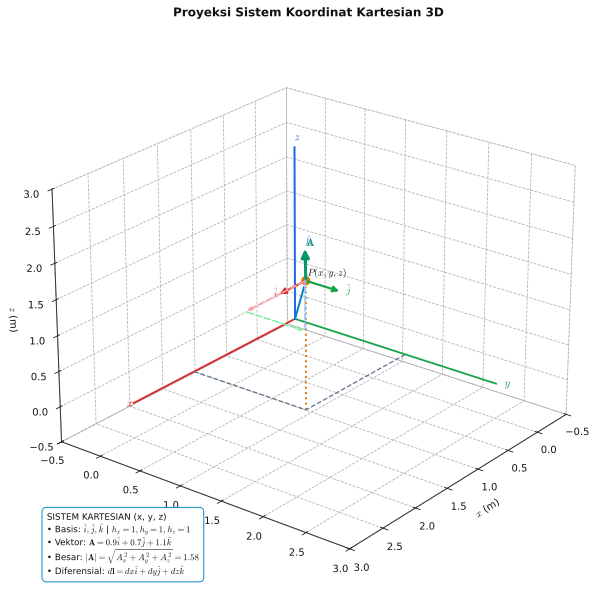

In [5]:
def plot_cartesian_projection_3d(x0=1.6, y0=1.4, z0=1.8):
    """Visualisasi Proyeksi 3D Sistem Koordinat Kartesian (x, y, z)."""
    fig = plt.figure(dpi=120)
    ax = fig.add_subplot(111, projection='3d')
    setup_3d_pane(ax, xlim=(-0.5, 3.0), ylim=(-0.5, 3.0), zlim=(-0.5, 3.0), axis_len=2.5)

    # Titik P
    ax.scatter([x0], [y0], [z0], color='#d97706', s=110, zorder=10, edgecolors='white', lw=1.2)
    ax.text(x0+0.1, y0+0.1, z0+0.15, r'$P(x,y,z)$', color='#111111', fontweight='bold', fontsize=10)

    # Proyeksi Kartesis
    ax.plot([x0, x0], [y0, y0], [0, z0], color='#d97706', ls=':', lw=2.0)
    ax.plot([0, x0], [y0, y0], [0, 0], color='#64748b', ls='--', lw=1.3)
    ax.plot([x0, x0], [0, y0], [0, 0], color='#64748b', ls='--', lw=1.3)
    ax.plot([0, x0], [0, y0], [0, z0], color='#0284c7', ls='-', lw=2.0)

    # Triad Vektor Satuan di P
    u_len = 0.42
    ax.add_artist(Arrow3D([x0, x0+u_len], [y0, y0], [z0, z0], mutation_scale=12, color='#dc2626', arrowstyle='-|>', lw=2.2))
    ax.text(x0+u_len+0.06, y0, z0, r'$\hat{i}$', color='#dc2626', fontweight='bold', fontsize=10)
    ax.add_artist(Arrow3D([x0, x0], [y0, y0+u_len], [z0, z0], mutation_scale=12, color='#16a34a', arrowstyle='-|>', lw=2.2))
    ax.text(x0, y0+u_len+0.06, z0, r'$\hat{j}$', color='#16a34a', fontweight='bold', fontsize=10)
    ax.add_artist(Arrow3D([x0, x0], [y0, y0], [z0, z0+u_len], mutation_scale=12, color='#2563eb', arrowstyle='-|>', lw=2.2))
    ax.text(x0, y0, z0+u_len+0.06, r'$\hat{k}$', color='#2563eb', fontweight='bold', fontsize=10)

    # Vektor Uji A
    Ax, Ay, Az = 0.9, 0.7, 1.1
    Amag = np.sqrt(Ax**2 + Ay**2 + Az**2)
    draw_vector_components_3d(ax, (x0, y0, z0), [(Ax, 0, 0), (0, Ay, 0), (0, 0, Az)])
    ax.add_artist(Arrow3D([x0, x0+Ax], [y0, y0+Ay], [z0, z0+Az], mutation_scale=16, color='#059669', arrowstyle='-|>', lw=3.0))
    ax.text(x0+Ax+0.07, y0+Ay+0.07, z0+Az+0.07, r'$\mathbf{A}$', color='#059669', fontweight='bold', fontsize=11)

    card1 = (
        "SISTEM KARTESIAN (x, y, z)\n"
        r"• Basis: $\hat{i}, \hat{j}, \hat{k}$ | $h_x=1, h_y=1, h_z=1$" + "\n"
        f"• Vektor: $\\mathbf{{A}} = {Ax:.1f}\\hat{{i}} + {Ay:.1f}\\hat{{j}} + {Az:.1f}\\hat{{k}}$\n"
        f"• Besar: $|\\mathbf{{A}}| = \\sqrt{{A_x^2+A_y^2+A_z^2}} = {Amag:.2f}$\n"
        r"• Diferensial: $d\mathbf{l}=dx\hat{i}+dy\hat{j}+dz\hat{k}$"
    )
    ax.text2D(0.04, 0.04, card1, transform=ax.transAxes, fontsize=8.8,
              bbox=dict(boxstyle='round,pad=0.55', facecolor='white', edgecolor='#0284c7', alpha=0.95),
              color='#111111')
    ax.set_title('Proyeksi Sistem Koordinat Kartesian 3D', color='#111111', fontsize=12, pad=12, fontweight='bold')
    ax.view_init(elev=24, azim=38)
    plt.tight_layout()
    plt.show()
    plt.close()

def plot_coordinate_projections_3d():
    plot_cartesian_projection_3d()
    
# Eksekusi ketiga visualisasi sebagai gambar masing-masing
plot_coordinate_projections_3d()

### Basis silinder
Basis silinder berputar mengikuti $\phi$:
$$\hat{\mathbf s}=\cos\phi\,\hat{\mathbf x}+\sin\phi\,\hat{\mathbf y},\qquad
\hat{\boldsymbol\phi}=-\sin\phi\,\hat{\mathbf x}+\cos\phi\,\hat{\mathbf y},\qquad
\hat{\mathbf z}=\hat{\mathbf z}.$$
Sebaliknya, $\hat{\mathbf x}=\cos\phi\,\hat{\mathbf s}-\sin\phi\,\hat{\boldsymbol\phi}$ dan $\hat{\mathbf y}=\sin\phi\,\hat{\mathbf s}+\cos\phi\,\hat{\boldsymbol\phi}$. Untuk vektor yang sama,
$$A_s=A_x\cos\phi+A_y\sin\phi,\quad A_\phi=-A_x\sin\phi+A_y\cos\phi,\quad A_z=A_z.$$


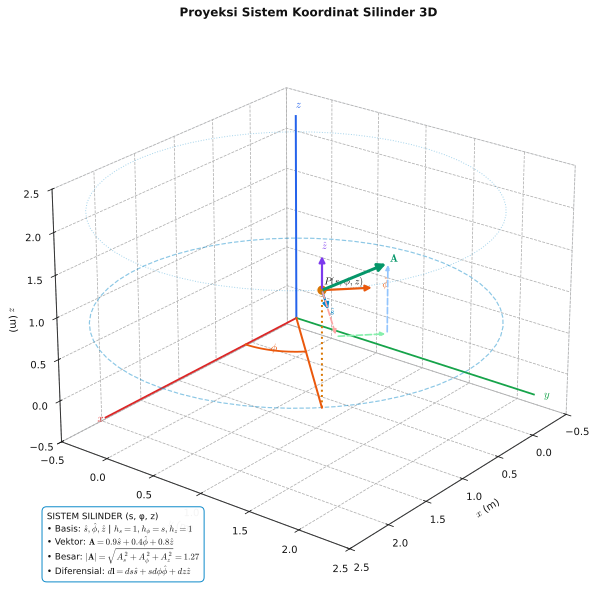

In [6]:
def plot_cylindrical_projection_3d(s0=1.8, phi0=np.pi/4, z0_cyl=1.4):
    """Visualisasi Proyeksi 3D Sistem Koordinat Silinder (s, phi, z)."""
    fig = plt.figure(dpi=120)
    ax = fig.add_subplot(111, projection='3d')
    setup_3d_pane(ax, xlim=(-0.5, 2.5), ylim=(-0.5, 2.5), zlim=(-0.5, 2.5), axis_len=2.5)

    xc = s0 * np.cos(phi0)
    yc = s0 * np.sin(phi0)
    zc = z0_cyl
    phi_c = np.linspace(0, 2*np.pi, 60)
    ax.plot(s0*np.cos(phi_c), s0*np.sin(phi_c), 0, color='#0284c7', lw=1.2, ls='--', alpha=0.45)
    ax.plot(s0*np.cos(phi_c), s0*np.sin(phi_c), zc, color='#0284c7', lw=1.0, ls=':', alpha=0.35)

    ax.scatter([xc], [yc], [zc], color='#d97706', s=110, zorder=10, edgecolors='white', lw=1.2)
    ax.text(xc+0.1, yc+0.1, zc+0.15, r'$P(s,\phi,z)$', color='#111111', fontweight='bold', fontsize=10)

    ax.plot([xc, xc], [yc, yc], [0, zc], color='#d97706', ls=':', lw=2.0)
    ax.plot([0, xc], [0, yc], [0, 0], color='#ea580c', ls='-', lw=2.0)
    arc_phi = np.linspace(0, phi0, 25)
    ax.plot(0.7*np.cos(arc_phi), 0.7*np.sin(arc_phi), 0, color='#ea580c', lw=1.8)
    ax.text(0.8*np.cos(phi0/2), 0.8*np.sin(phi0/2), 0.05, r'$\phi$', color='#ea580c', fontweight='bold', fontsize=11)

    # Triad Silinder di P
    u_len = 0.42
    ax.add_artist(Arrow3D([xc, xc+u_len*np.cos(phi0)], [yc, yc+u_len*np.sin(phi0)], [zc, zc],
                          mutation_scale=12, color='#0284c7', arrowstyle='-|>', lw=2.2))
    ax.text(xc+u_len*np.cos(phi0)+0.05, yc+u_len*np.sin(phi0)+0.05, zc, r'$\hat{s}$', color='#0284c7', fontweight='bold', fontsize=10)
    ax.add_artist(Arrow3D([xc, xc-u_len*np.sin(phi0)], [yc, yc+u_len*np.cos(phi0)], [zc, zc],
                          mutation_scale=12, color='#ea580c', arrowstyle='-|>', lw=2.2))
    ax.text(xc-u_len*np.sin(phi0)-0.05, yc+u_len*np.cos(phi0)+0.05, zc, r'$\hat{\phi}$', color='#ea580c', fontweight='bold', fontsize=10)
    ax.add_artist(Arrow3D([xc, xc], [yc, yc], [zc, zc+u_len], mutation_scale=12, color='#7c3aed', arrowstyle='-|>', lw=2.2))
    ax.text(xc, yc, zc+u_len+0.06, r'$\hat{z}$', color='#7c3aed', fontweight='bold', fontsize=10)

    # Vektor Uji A
    As, Aphi, Az = 0.9, 0.4, 0.8
    Amag_cyl = np.sqrt(As**2 + Aphi**2 + Az**2)
    Ax_c = As*np.cos(phi0) - Aphi*np.sin(phi0)
    Ay_c = As*np.sin(phi0) + Aphi*np.cos(phi0)
    draw_vector_components_3d(ax, (xc, yc, zc), [
        (As*np.cos(phi0), As*np.sin(phi0), 0),
        (-Aphi*np.sin(phi0), Aphi*np.cos(phi0), 0),
        (0, 0, Az),
    ])
    ax.add_artist(Arrow3D([xc, xc+Ax_c], [yc, yc+Ay_c], [zc, zc+Az], mutation_scale=16, color='#059669', arrowstyle='-|>', lw=3.0))
    ax.text(xc+Ax_c+0.07, yc+Ay_c+0.07, zc+Az+0.07, r'$\mathbf{A}$', color='#059669', fontweight='bold', fontsize=11)

    card2 = (
        "SISTEM SILINDER (s, φ, z)\n"
        r"• Basis: $\hat{s}, \hat{\phi}, \hat{z}$ | $h_s=1, h_\phi=s, h_z=1$" + "\n"
        f"• Vektor: $\\mathbf{{A}} = {As:.1f}\\hat{{s}} + {Aphi:.1f}\\hat{{\\phi}} + {Az:.1f}\\hat{{z}}$\n"
        f"• Besar: $|\\mathbf{{A}}| = \\sqrt{{A_s^2+A_\\phi^2+A_z^2}} = {Amag_cyl:.2f}$\n"
        r"• Diferensial: $d\mathbf{l}=ds\hat{s}+sd\phi\hat{\phi}+dz\hat{z}$"
    )
    ax.text2D(0.04, 0.04, card2, transform=ax.transAxes, fontsize=8.8,
              bbox=dict(boxstyle='round,pad=0.55', facecolor='white', edgecolor='#0284c7', alpha=0.95),
              color='#111111')
    ax.set_title('Proyeksi Sistem Koordinat Silinder 3D', color='#111111', fontsize=12, pad=12, fontweight='bold')
    ax.view_init(elev=24, azim=38)
    plt.tight_layout()
    plt.show()
    plt.close()

def plot_coordinate_projections_3d():
    plot_cylindrical_projection_3d()


# Eksekusi ketiga visualisasi sebagai gambar masing-masing
plot_coordinate_projections_3d()

### Basis bola
$$\hat{\mathbf r}=\sin\theta\cos\phi\,\hat{\mathbf x}+\sin\theta\sin\phi\,\hat{\mathbf y}+\cos\theta\,\hat{\mathbf z},$$
$$\hat{\boldsymbol\theta}=\cos\theta\cos\phi\,\hat{\mathbf x}+\cos\theta\sin\phi\,\hat{\mathbf y}-\sin\theta\,\hat{\mathbf z},$$
$$\hat{\boldsymbol\phi}=-\sin\phi\,\hat{\mathbf x}+\cos\phi\,\hat{\mathbf y}.$$
Komponen bola adalah proyeksi: $A_r=\mathbf A\cdot\hat{\mathbf r}$, $A_\theta=\mathbf A\cdot\hat{\boldsymbol\theta}$, dan $A_\phi=\mathbf A\cdot\hat{\boldsymbol\phi}$. Ketiga basis ini ortonormal dan membentuk triad tangan kanan.

Penting: vektor fisik tidak berubah oleh transformasi koordinat. Yang ditransformasikan adalah komponennya terhadap basis lokal yang berbeda. Karena basis silinder dan bola berubah terhadap posisi, turunan komponen saja belum cukup untuk menghitung turunan vektor; perubahan arah basis juga tercakup dalam faktor geometri operator diferensial.

### Aljabar vektor yang dipakai untuk proyeksi
Untuk vektor nyata $\mathbf A$ dan $\mathbf B$, hasil kali titik $\mathbf A\cdot\mathbf B=|\mathbf A||\mathbf B|\cos\alpha$ adalah skalar dan mengukur proyeksi; jika $\hat{\mathbf e}$ satuan, maka komponen skalar $A_e=\mathbf A\cdot\hat{\mathbf e}$. Hasil kali silang $\mathbf A\times\mathbf B$ tegak lurus kedua vektor, besarnya $|\mathbf A||\mathbf B|\sin\alpha$, dan arahnya mengikuti kaidah tangan kanan. Oleh karena itu, urutan vektor pada hasil kali silang penting.

Untuk triad ortonormal tangan kanan, $\hat{\mathbf e}_1\times\hat{\mathbf e}_2=\hat{\mathbf e}_3$ (siklis), sedangkan pertukaran dua faktor membalik tanda. Produk tripel skalar $\mathbf A\cdot(\mathbf B\times\mathbf C)$ memberi volume berarah; nilai mutlaknya adalah volume jajaran genjang ruang yang dibangun ketiga vektor. Konsep ini membantu memeriksa orientasi basis serta arah elemen luas bervektor $d\mathbf a$.

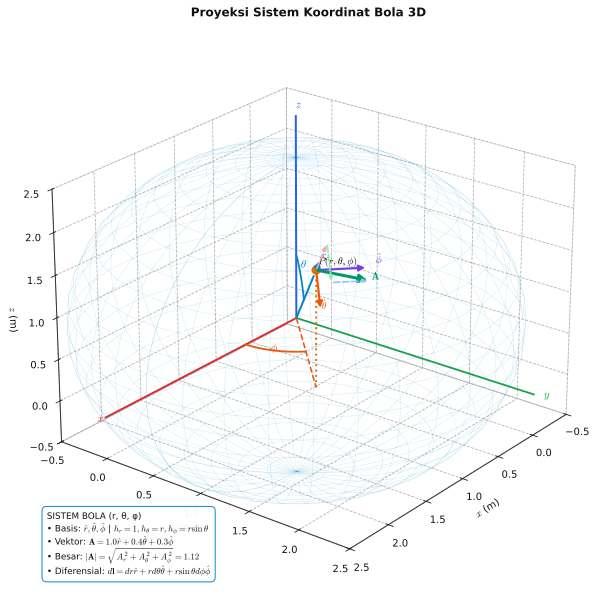

In [7]:
def plot_spherical_projection_3d(r0=2.0, th0=np.pi/4, phi0_sph=np.pi/4):
    """Visualisasi Proyeksi 3D Sistem Koordinat Bola (r, theta, phi)."""
    fig = plt.figure(dpi=120)
    ax = fig.add_subplot(111, projection='3d')
    setup_3d_pane(ax, xlim=(-0.5, 2.5), ylim=(-0.5, 2.5), zlim=(-0.5, 2.5), axis_len=2.5)

    xs = r0 * np.sin(th0) * np.cos(phi0_sph)
    ys = r0 * np.sin(th0) * np.sin(phi0_sph)
    zs = r0 * np.cos(th0)

    th_grid = np.linspace(0, np.pi, 25)
    phi_grid = np.linspace(0, 2*np.pi, 35)
    TH, PH = np.meshgrid(th_grid, phi_grid)
    XS = r0 * np.sin(TH) * np.cos(PH)
    YS = r0 * np.sin(TH) * np.sin(PH)
    ZS = r0 * np.cos(TH)
    ax.plot_wireframe(XS, YS, ZS, color='#0284c7', lw=0.4, alpha=0.22)

    ax.scatter([xs], [ys], [zs], color='#d97706', s=110, zorder=10, edgecolors='white', lw=1.2)
    ax.text(xs+0.1, ys+0.1, zs+0.15, r'$P(r,\theta,\phi)$', color='#111111', fontweight='bold', fontsize=10)

    ax.plot([0, xs], [0, ys], [0, zs], color='#0284c7', ls='-', lw=2.0)
    ax.plot([xs, xs], [ys, ys], [0, zs], color='#d97706', ls=':', lw=2.0)
    ax.plot([0, xs], [0, ys], [0, 0], color='#ea580c', ls='--', lw=1.6)

    arc_th = np.linspace(0, th0, 20)
    ax.plot(0.8*np.sin(arc_th)*np.cos(phi0_sph), 0.8*np.sin(arc_th)*np.sin(phi0_sph), 0.8*np.cos(arc_th), color='#0284c7', lw=1.8)
    ax.text(0.9*np.sin(th0/2)*np.cos(phi0_sph), 0.9*np.sin(th0/2)*np.sin(phi0_sph), 0.9*np.cos(th0/2), r'$\theta$', color='#0284c7', fontweight='bold', fontsize=11)

    arc_phi_s = np.linspace(0, phi0_sph, 20)
    ax.plot(0.7*np.cos(arc_phi_s), 0.7*np.sin(arc_phi_s), 0, color='#ea580c', lw=1.8)
    ax.text(0.8*np.cos(phi0_sph/2), 0.8*np.sin(phi0_sph/2), 0.05, r'$\phi$', color='#ea580c', fontweight='bold', fontsize=11)

    # Triad Bola di P
    u_len = 0.42
    rx = np.sin(th0)*np.cos(phi0_sph); ry = np.sin(th0)*np.sin(phi0_sph); rz = np.cos(th0)
    ax.add_artist(Arrow3D([xs, xs+u_len*rx], [ys, ys+u_len*ry], [zs, zs+u_len*rz],
                          mutation_scale=12, color='#0284c7', arrowstyle='-|>', lw=2.2))
    ax.text(xs+u_len*rx+0.05, ys+u_len*ry+0.05, zs+u_len*rz+0.05, r'$\hat{r}$', color='#0284c7', fontweight='bold', fontsize=10)
    tx = np.cos(th0)*np.cos(phi0_sph); ty = np.cos(th0)*np.sin(phi0_sph); tz = -np.sin(th0)
    ax.add_artist(Arrow3D([xs, xs+u_len*tx], [ys, ys+u_len*ty], [zs, zs+u_len*tz],
                          mutation_scale=12, color='#ea580c', arrowstyle='-|>', lw=2.2))
    ax.text(xs+u_len*tx+0.05, ys+u_len*ty+0.05, zs+u_len*tz+0.05, r'$\hat{\theta}$', color='#ea580c', fontweight='bold', fontsize=10)
    px = -np.sin(phi0_sph); py = np.cos(phi0_sph); pz = 0.0
    ax.add_artist(Arrow3D([xs, xs+u_len*px], [ys, ys+u_len*py], [zs, zs+u_len*pz],
                          mutation_scale=12, color='#7c3aed', arrowstyle='-|>', lw=2.2))
    ax.text(xs+u_len*px-0.05, ys+u_len*py+0.05, zs+0.05, r'$\hat{\phi}$', color='#7c3aed', fontweight='bold', fontsize=10)

    # Vektor Uji A
    Ar, Ath, Aphi = 1.0, 0.4, 0.3
    Amag_sph = np.sqrt(Ar**2 + Ath**2 + Aphi**2)
    Ax_s = Ar*rx + Ath*tx + Aphi*px
    Ay_s = Ar*ry + Ath*ty + Aphi*py
    Az_s = Ar*rz + Ath*tz + Aphi*pz
    draw_vector_components_3d(ax, (xs, ys, zs), [
        (Ar*rx, Ar*ry, Ar*rz),
        (Ath*tx, Ath*ty, Ath*tz),
        (Aphi*px, Aphi*py, Aphi*pz),
    ])
    ax.add_artist(Arrow3D([xs, xs+Ax_s], [ys, ys+Ay_s], [zs, zs+Az_s], mutation_scale=16, color='#059669', arrowstyle='-|>', lw=3.0))
    ax.text(xs+Ax_s+0.07, ys+Ay_s+0.07, zs+Az_s+0.07, r'$\mathbf{A}$', color='#059669', fontweight='bold', fontsize=11)

    card3 = (
        "SISTEM BOLA (r, θ, φ)\n"
        r"• Basis: $\hat{r}, \hat{\theta}, \hat{\phi}$ | $h_r=1, h_\theta=r, h_\phi=r\sin\theta$" + "\n"
        f"• Vektor: $\\mathbf{{A}} = {Ar:.1f}\\hat{{r}} + {Ath:.1f}\\hat{{\\theta}} + {Aphi:.1f}\\hat{{\\phi}}$\n"
        f"• Besar: $|\\mathbf{{A}}| = \\sqrt{{A_r^2+A_\\theta^2+A_\\phi^2}} = {Amag_sph:.2f}$\n"
        r"• Diferensial: $d\mathbf{l}=dr\hat{r}+rd\theta\hat{\theta}+r\sin\theta d\phi\hat{\phi}$"
    )
    ax.text2D(0.04, 0.04, card3, transform=ax.transAxes, fontsize=8.8,
              bbox=dict(boxstyle='round,pad=0.55', facecolor='white', edgecolor='#0284c7', alpha=0.95),
              color='#111111')
    ax.set_title('Proyeksi Sistem Koordinat Bola 3D', color='#111111', fontsize=12, pad=12, fontweight='bold')
    ax.view_init(elev=24, azim=38)
    plt.tight_layout()
    plt.show()
    plt.close()

def plot_coordinate_projections_3d():
    plot_spherical_projection_3d()

# Eksekusi ketiga visualisasi sebagai gambar masing-masing
plot_coordinate_projections_3d()

### Faktor skala dan metrik koordinat ortogonal

Untuk koordinat ortogonal $(q_1,q_2,q_3)$, perubahan kecil koordinat $dq_i$ menghasilkan perpindahan fisik sepanjang arah basis $\hat{\mathbf e}_i$ sebesar $h_i\,dq_i$, dengan $h_i$ faktor skala. Karena arahnya saling tegak lurus,
$$d\mathbf l=\sum_i h_i\,dq_i\,\hat{\mathbf e}_i,\qquad ds^2=\sum_i h_i^2dq_i^2.$$
Besaran $ds^2$ adalah metrik (kuadrat jarak). Faktor skala mengubah perubahan koordinat menjadi jarak fisik; ia bukan faktor yang mengubah nilai komponen vektor fisik.

| Sistem | $(q_1,q_2,q_3)$ | $(h_1,h_2,h_3)$ | $d\ell^2$ |
|---|---|---|---|
| Kartesian | $(x,y,z)$ | $(1,1,1)$ | $dx^2+dy^2+dz^2$ |
| Silinder | $(s,\phi,z)$ | $(1,s,1)$ | $ds^2+s^2d\phi^2+dz^2$ |
| Bola | $(r,\theta,\phi)$ | $(1,r,r\sin\theta)$ | $dr^2+r^2d\theta^2+r^2\sin^2\theta\,d\phi^2$ |

Maka elemen panjang vektor adalah $d\mathbf l=h_1dq_1\hat{\mathbf e}_1+h_2dq_2\hat{\mathbf e}_2+h_3dq_3\hat{\mathbf e}_3$. Untuk komponen fisik $\mathbf A=\sum_i A_i\hat{\mathbf e}_i$, norma tetap $|\mathbf A|=\sqrt{A_1^2+A_2^2+A_3^2}$ karena basis lokal adalah ortonormal. Bentuk umum $h_i$ ini adalah generalisasi koordinat ortogonal; pada pembahasan utama Griffiths §1.4, elemen-elemen bola dan silinder diturunkan langsung dari geometri.

### Elemen panjang, luas, dan volume
Untuk koordinat ortogonal:
$$d\tau=h_1h_2h_3\,dq_1dq_2dq_3,$$
dan pada permukaan koordinat $q_i=$ konstan, besar elemen luas adalah $d a_i=h_jh_k\,dq_jdq_k$ dengan normal $\pm\hat{\mathbf e}_i$. Arah tanda dipilih dari orientasi permukaan; tidak ada satu elemen luas vektor yang berlaku untuk semua orientasi.

| Sistem | $d\mathbf l$ | Elemen volume $d\tau$ | Contoh elemen luas |
|---|---|---|---|
| Kartesian | $dx\hat x+dy\hat y+dz\hat z$ | $dx\,dy\,dz$ | $dy\,dz\,\hat x$ |
| Silinder | $ds\hat s+s\,d\phi\hat\phi+dz\hat z$ | $s\,ds\,d\phi\,dz$ | sisi $s=$ konstan: $s\,d\phi\,dz\,\hat s$ |
| Bola | $dr\hat r+r\,d\theta\hat\theta+r\sin\theta\,d\phi\hat\phi$ | $r^2\sin\theta\,dr\,d\theta\,d\phi$ | kulit $r=$ konstan: $r^2\sin\theta\,d\theta\,d\phi\,\hat r$ |

Sebagai contoh, pada bola $r=R$, $d\mathbf a=R^2\sin\theta\,d\theta\,d\phi\,\hat r$; pada bidang $xy$ berorientasi ke $+z$ yang sama dengan $\theta=\pi/2$, $d\mathbf a=-r\,dr\,d\phi\,\hat\theta$. Luas kulit bola adalah $\int_0^{2\pi}\!\int_0^\pi R^2\sin\theta\,d\theta\,d\phi=4\pi R^2$. Faktor $\sin\theta$ berasal dari penyusutan lingkaran lintang menuju kutub.

### Operator diferensial pada koordinat ortogonal

Rumus berikut memakai **komponen fisik** $A_i$ pada basis satuan lokal $\hat{\mathbf e}_i$, bukan komponen terhadap vektor koordinat $\partial\mathbf r/\partial q_i$. Faktor skala harus dipakai secara konsisten. Notasi $\nabla$ (del) tampak seperti vektor, tetapi merupakan operator diferensial: ia baru bermakna setelah bertindak pada medan skalar atau vektor. Ekspresi eksplisit bola dan silinder adalah materi Griffiths §1.4; bentuk umum untuk setiap koordinat ortogonal yang ditampilkan di sini adalah generalisasi dari faktor skala.

### Gradien skalar
Perubahan $df$ sepanjang arah $\hat{\mathbf e}_i$ per satuan panjang adalah $(1/h_i)\,\partial f/\partial q_i$, sehingga
$$\nabla f=\sum_i\hat{\mathbf e}_i\frac{1}{h_i}\frac{\partial f}{\partial q_i}.$$
Karena $df=\nabla f\cdot d\mathbf l$, gradien mengarah ke kenaikan terbesar $f$; besarannya adalah laju kenaikan maksimum per satuan jarak. Secara eksplisit:
$$\nabla f=\hat s\,\partial_s f+\hat\phi\,\frac{1}{s}\partial_\phi f+\hat z\,\partial_z f,$$
$$\nabla f=\hat r\,\partial_r f+\hat\theta\,\frac{1}{r}\partial_\theta f+\hat\phi\,\frac{1}{r\sin\theta}\partial_\phi f.$$

### Divergensi vektor
Divergensi adalah fluks keluar bersih per satuan volume dalam limit lokal. Nilai positif menandai perilaku sumber dan nilai negatif perilaku serapan; besaran ini skalar. Dengan faktor skala $(h_1,h_2,h_3)$:
$$\nabla\cdot\mathbf A=\frac{1}{h_1h_2h_3}\left[\frac{\partial(h_2h_3A_1)}{\partial q_1}+\frac{\partial(h_3h_1A_2)}{\partial q_2}+\frac{\partial(h_1h_2A_3)}{\partial q_3}\right].$$
Dalam silinder dan bola:
$$\nabla\cdot\mathbf A=\frac{1}{s}\partial_s(sA_s)+\frac{1}{s}\partial_\phi A_\phi+\partial_z A_z,$$
$$\nabla\cdot\mathbf A=\frac{1}{r^2}\partial_r(r^2A_r)+\frac{1}{r\sin\theta}\partial_\theta(\sin\theta A_\theta)+\frac{1}{r\sin\theta}\partial_\phi A_\phi.$$

### Curl vektor
Curl mengukur sirkulasi lokal per luas berarah; hasilnya vektor yang arahnya ditentukan orientasi tangan kanan. Bentuk determinan mnemonik untuk sistem ortogonal adalah
$$\nabla\times\mathbf A=\frac{1}{h_1h_2h_3}\begin{vmatrix}h_1\hat{\mathbf e}_1&h_2\hat{\mathbf e}_2&h_3\hat{\mathbf e}_3\\\partial_{q_1}&\partial_{q_2}&\partial_{q_3}\\h_1A_1&h_2A_2&h_3A_3\end{vmatrix}.$$
Ekspansi silinder:
$$(\nabla\times\mathbf A)_s=\frac{1}{s}\partial_\phi A_z-\partial_z A_\phi,\quad
(\nabla\times\mathbf A)_\phi=\partial_z A_s-\partial_s A_z,\quad
(\nabla\times\mathbf A)_z=\frac{1}{s}\left[\partial_s(sA_\phi)-\partial_\phi A_s\right].$$
Ekspansi bola:
$$(\nabla\times\mathbf A)_r=\frac{1}{r\sin\theta}\left[\partial_\theta(\sin\theta A_\phi)-\partial_\phi A_\theta\right],$$
$$(\nabla\times\mathbf A)_\theta=\frac{1}{r}\left[\frac{1}{\sin\theta}\partial_\phi A_r-\partial_r(rA_\phi)\right],\quad
(\nabla\times\mathbf A)_\phi=\frac{1}{r}\left[\partial_r(rA_\theta)-\partial_\theta A_r\right].$$

### Laplacian skalar
Laplacian skalar adalah $\nabla^2f=\nabla\cdot(\nabla f)$. Dalam koordinat ortogonal,
$$\nabla^2f=\frac{1}{h_1h_2h_3}\sum_i\frac{\partial}{\partial q_i}\left(\frac{h_1h_2h_3}{h_i^2}\frac{\partial f}{\partial q_i}\right).$$
Identitas $\nabla\cdot(\nabla\times\mathbf A)=0$ dan $\nabla\times(\nabla f)=\mathbf 0$ berlaku untuk medan yang cukup mulus pada daerahnya. Titik singular dan diskontinuitas harus diperlakukan terpisah, bukan dimasukkan begitu saja ke identitas lokal tersebut. Karena itu:
$$\nabla^2f=\frac{1}{s}\partial_s(s\partial_s f)+\frac{1}{s^2}\partial_\phi^2f+\partial_z^2f$$
untuk silinder, dan
$$\nabla^2f=\frac{1}{r^2}\partial_r(r^2\partial_r f)+\frac{1}{r^2\sin\theta}\partial_\theta(\sin\theta\,\partial_\theta f)+\frac{1}{r^2\sin^2\theta}\partial_\phi^2f$$
untuk bola. Untuk fungsi yang hanya bergantung pada $r$, $\nabla^2f=(1/r^2)\,d(r^2f')/dr$; bentuk satu variabel ini sangat berguna dalam masalah potensial bersimetri bola.

### Makna integral dan teorema dasar

Sebelum memakai teorema integral, bedakan tiga jenis integral yang lazim dalam elektromagnetisme:

- **Integral garis** $\int_C\mathbf A\cdot d\mathbf l$ menjumlahkan komponen tangensial medan sepanjang lintasan berarah. Nilainya umumnya bergantung pada lintasan; untuk medan gradien yang mulus pada daerah simply connected, integralnya hanya bergantung pada titik ujung.
- **Integral permukaan atau fluks** $\int_S\mathbf A\cdot d\mathbf a$ menjumlahkan komponen normal medan. Untuk permukaan terbuka, orientasi normal harus dipilih; untuk permukaan tertutup, konvensinya adalah normal ke luar.
- **Integral volume** $\int_V f\,d\tau$ menjumlahkan rapat skalar di dalam volume. Integral vektor dapat dihitung per komponen pada basis Kartesian yang tetap; pada basis kurvilinear yang berubah, basis tidak boleh dikeluarkan dari integral tanpa alasan.

Bentuk integral dari teorema gradien fundamental adalah
$$\int_a^b\nabla f\cdot d\mathbf l=f(b)-f(a).$$
Akibatnya, integral garis medan gradien sepanjang lintasan tertutup nol. Sebaliknya, integral tertutup nol saja tidak selalu cukup untuk menyimpulkan medan adalah gradien global jika daerah memiliki lubang atau singularitas.

Divergensi dan curl menghubungkan medan lokal dengan integral global:
$$\iiint_{\mathcal V}(\nabla\cdot\mathbf A)\,d\tau=\oiint_{\partial\mathcal V}\mathbf A\cdot d\mathbf a$$
(teorema divergensi), dan
$$\iint_{\mathcal S}(\nabla\times\mathbf A)\cdot d\mathbf a=\oint_{\partial\mathcal S}\mathbf A\cdot d\mathbf l$$
(teorema Stokes). Orientasi batas harus konsisten: normal permukaan dan arah lintasan terkait oleh kaidah tangan kanan. Rumus integral ini memerlukan medan dan daerah yang cukup teratur; singularitas di dalam volume atau permukaan harus dikecualikan atau ditangani dalam pengertian distribusi.

Dalam elektrostatis, $\nabla\cdot\mathbf E=\rho/\epsilon_0$ dan $\nabla\times\mathbf E=0$. Koordinat bola menyederhanakan medan muatan titik atau distribusi bola; koordinat silinder menyederhanakan kawat atau distribusi silinder. Teorema integral tetap berlaku di semua koordinat—yang berubah hanya representasi $d\mathbf a$, $d\mathbf l$, dan $d\tau$.

## Contoh kerja: operator dalam koordinat kurvilinear

### Contoh A — divergensi medan radial bola
Untuk $\mathbf A=f(r)\hat r$, semua komponen sudut lenyap dan
$$\nabla\cdot\mathbf A=\frac{1}{r^2}\frac{d}{dr}\big(r^2f(r)\big).$$
Jika $f(r)=Cr$, diperoleh $\nabla\cdot\mathbf A=3C$. Jika $f(r)=C/r^2$, divergensinya nol untuk $r>0$. Namun medan $C\hat r/r^2$ singular di asal; pernyataan nol hanya berlaku di ruang yang tidak memuat titik asal. Fluks melalui bola berjari-jari $R$ berapa pun adalah $4\pi C$. Karena itu divergensi distribusionalnya adalah
$$\nabla\cdot\left(\frac{\hat r}{r^2}\right)=4\pi\,\delta^{(3)}(\mathbf r),\qquad \nabla\cdot\left(C\frac{\hat r}{r^2}\right)=4\pi C\,\delta^{(3)}(\mathbf r).$$
Di sini delta tiga dimensi didefinisikan oleh $\int_V f(\mathbf r)\delta^{(3)}(\mathbf r)\,d\tau=f(\mathbf 0)$ jika asal berada di dalam $V$, dan nol jika asal di luar. Dengan demikian, integralnya atas bola memberi $4\pi C$, sesuai fluks dan teorema divergensi. Untuk medan listrik Coulomb, $C=q/(4\pi\epsilon_0)$ sehingga hasilnya $q\delta^{(3)}(\mathbf r)/\epsilon_0$, persis bentuk sumber titik pada Hukum Gauss. Ini contoh bahwa singularitas sumber bukan sekadar masalah faktor skala atau basis koordinat.

### Contoh B — curl medan azimutal silinder
Ambil $\mathbf A=\omega s\hat\phi$, dengan $\omega$ konstan. Satu-satunya komponen curl yang tidak nol adalah
$$(\nabla\times\mathbf A)_z=\frac{1}{s}\frac{d}{ds}(sA_\phi)=\frac{1}{s}\frac{d}{ds}(\omega s^2)=2\omega.$$
Faktor $s$ di dalam turunan berasal dari ukuran lingkaran, sedangkan faktor $1/s$ di luar mengubah hasil menjadi besaran per luas.

In [8]:
import sympy as sp

r_sym, s_sym, C, omega = sp.symbols("r s C omega", positive=True)
div_Cr = sp.simplify(sp.diff(r_sym**2 * (C * r_sym), r_sym) / r_sym**2)
div_inverse_square = sp.simplify(sp.diff(r_sym**2 * (C / r_sym**2), r_sym) / r_sym**2)
curl_azimuthal_z = sp.simplify(sp.diff(s_sym * (omega * s_sym), s_sym) / s_sym)

print("div(C r r_hat)       =", div_Cr)
print("div(C/r^2 r_hat), r>0 =", div_inverse_square)
print("curl(omega s phi_hat)_z =", curl_azimuthal_z)

div(C r r_hat)       = 3*C
div(C/r^2 r_hat), r>0 = 0
curl(omega s phi_hat)_z = 2*omega


### Contoh C — memeriksa identitas $\nabla\cdot(\nabla\times\mathbf A)=0$
Identitas ini berlaku untuk medan yang cukup mulus pada daerah yang dipertimbangkan. Pemeriksaan simbolik sederhana di bawah memakai medan $\mathbf A=s^2\hat\phi$ pada koordinat silinder.

In [9]:
s_sym, phi_sym, z_sym = sp.symbols("s phi z", positive=True, real=True)
A_s, A_phi, A_z = 0, s_sym**2, 0
curl_s = sp.diff(A_z, phi_sym) / s_sym - sp.diff(A_phi, z_sym)
curl_phi = sp.diff(A_s, z_sym) - sp.diff(A_z, s_sym)
curl_z = (sp.diff(s_sym * A_phi, s_sym) - sp.diff(A_s, phi_sym)) / s_sym
div_curl = (
    sp.diff(s_sym * curl_s, s_sym) / s_sym
    + sp.diff(curl_phi, phi_sym) / s_sym
    + sp.diff(curl_z, z_sym)
)
print("curl A =", (curl_s, curl_phi, curl_z))
print("div(curl A) =", sp.simplify(div_curl))

curl A = (0, 0, 3*s)
div(curl A) = 0


## Griffiths §1.5 — Delta Dirac dan singularitas koordinat

### Mengapa medan $\hat r/r^2$ mempunyai sumber titik?
Untuk $r>0$, rumus divergensi radial memberi $\nabla\cdot(\hat r/r^2)=r^{-2}\,d(1)/dr=0$. Namun fluks melalui bola berjari-jari $R$ tetap $4\pi$ untuk setiap $R>0$. Kedua fakta ini konsisten: rumus turunan biasa tidak mencakup titik singular $r=0$; seluruh kontribusi sumber berada di titik itu.

### Delta Dirac satu dimensi
Delta Dirac adalah distribusi, bukan fungsi biasa dengan tinggi berhingga. Ia ditentukan melalui aksinya di bawah integral: untuk fungsi uji kontinu $f$,
$$\int_{-\infty}^{\infty}f(x)\delta(x-a)\,dx=f(a),\qquad \int_{-\infty}^{\infty}\delta(x-a)\,dx=1.$$
Jika titik $a$ berada di luar daerah integrasi, integral nol. Delta memiliki satuan kebalikan satuan argumennya (misalnya m$^{-1}$ untuk $x$ berdimensi panjang). Untuk $k\ne0$ berlaku aturan skala $\delta(kx)=\delta(x)/|k|$; nilai mutlak diperlukan karena delta adalah rapat berukuran positif dan perubahan variabel dapat membalik orientasi sumbu. Kesamaan distribusi harus dimaknai melalui integral terhadap setiap fungsi uji.

Fungsi langkah Heaviside $H(x)$, yang bernilai nol untuk $x<0$ dan satu untuk $x>0$, memenuhi $dH/dx=\delta(x)$ dalam pengertian distribusi. Demikian pula $x\,\delta'(x)=-\delta(x)$; identitas turunan ini digunakan melalui integrasi parsial, bukan dengan manipulasi nilai titik delta.

### Delta tiga dimensi dan identitas sumber titik
Dalam Kartesian,
$$\delta^{(3)}(\mathbf r)=\delta(x)\delta(y)\delta(z),\qquad \int_{\mathbb R^3}f(\mathbf r)\delta^{(3)}(\mathbf r-\mathbf a)\,d\tau=f(\mathbf a).$$
Normalisasi ini harus konsisten dengan elemen volume kurvilinear, misalnya $d\tau=r^2\sin\theta\,dr\,d\theta\,d\phi$ dalam bola. Kesetaraan distribusional yang menyelesaikan paradoks fluks di atas adalah
$$\nabla\cdot\frac{\hat r}{r^2}=4\pi\delta^{(3)}(\mathbf r),\qquad \nabla^2\frac{1}{r}=-4\pi\delta^{(3)}(\mathbf r).$$
Untuk sumber di $\mathbf r'$, gantikan $\mathbf r$ dengan vektor pemisah $\boldsymbol{\mathcal R}=\mathbf r-\mathbf r'$ dan delta dengan $\delta^{(3)}(\mathbf r-\mathbf r')$. Dalam elektrostatika, $\mathbf E=q\hat r/(4\pi\epsilon_0r^2)$ karenanya memenuhi $\nabla\cdot\mathbf E=(q/\epsilon_0)\delta^{(3)}(\mathbf r)$.

### Singularitas koordinat (berbeda dari delta sumber)
1. **Sumbu silinder ($s=0$):** azimut $\phi$ dan arah $\hat s,\hat\phi$ tidak unik. Ini tidak otomatis berarti medan fisik singular; komponen basis bisa tidak terdefinisi sementara vektornya tetap mulus.
2. **Asal bola ($r=0$) dan kutub ($\sin\theta=0$):** satu atau lebih sudut/basis lokal tidak unik. Periksa medan dalam Kartesian atau gunakan limit untuk membedakan singularitas koordinat dari singularitas fisik.
3. **Lupa faktor skala:** misalnya panjang azimut silinder adalah $s\,d\phi$, bukan $d\phi$. Kesalahan ini mengubah divergensi, curl, dan integral.
4. **Mencampur komponen:** rumus operator di modul ini membutuhkan komponen fisik terhadap basis satuan lokal; komponen pada basis koordinat memiliki faktor skala berbeda.
5. **Menganggap basis kurvilinear konstan:** $\hat s,\hat\phi,\hat r,\hat\theta,\hat\phi$ berubah terhadap posisi. Karena itu rumus komponen Kartesian tidak bisa langsung diterapkan.
6. **Konvensi sudut berbeda:** selalu periksa apakah sudut polar diukur dari sumbu $+z$ atau dari bidang ekuator, dan apakah simbol azimut/polar tertukar.
7. **Membagi dengan nol pada komputasi:** tangani kasus $r=0$, $s=0$, atau $\sin\theta=0$ sebelum menghitung sudut atau basis.

Pemeriksaan praktis yang membantu: bandingkan norma vektor di dua basis, konversikan kembali ke Kartesian, cek satuan dimensi, dan periksa fluks/sirkulasi integral pada geometri sederhana.

## 4. Ringkasan Rumus Koordinat Ortogonal dan Operator Diferensial

Berikut adalah tabel komprehensif faktor skala, elemen diferensial, dan operator kalkulus vektor untuk ketiga sistem koordinat ortogonal standar:

| Karakteristik / Operator | Kartesian $(x, y, z)$ | Silinder $(s, \phi, z)$ | Bola $(r, \theta, \phi)$ |
| :--- | :---: | :---: | :---: |
| **Faktor Skala $(h_1, h_2, h_3)$** | $(1, 1, 1)$ | $(1, s, 1)$ | $(1, r, r\sin\theta)$ |
| **Elemen Panjang $d\mathbf{l}$** | $dx\,\hat{\mathbf{x}} + dy\,\hat{\mathbf{y}} + dz\,\hat{\mathbf{z}}$ | $ds\,\hat{\mathbf{s}} + s\,d\phi\,\hat{\boldsymbol{\phi}} + dz\,\hat{\mathbf{z}}$ | $dr\,\hat{\mathbf{r}} + r\,d\theta\,\hat{\boldsymbol{\theta}} + r\sin\theta\,d\phi\,\hat{\boldsymbol{\phi}}$ |
| **Elemen Volume $d\tau$** | $dx\,dy\,dz$ | $s\,ds\,d\phi\,dz$ | $r^2\sin\theta\,dr\,d\theta\,d\phi$ |
| **Gradien $\nabla f$** | $\dfrac{\partial f}{\partial x}\hat{\mathbf{x}} + \dfrac{\partial f}{\partial y}\hat{\mathbf{y}} + \dfrac{\partial f}{\partial z}\hat{\mathbf{z}}$ | $\dfrac{\partial f}{\partial s}\hat{\mathbf{s}} + \dfrac{1}{s}\dfrac{\partial f}{\partial \phi}\hat{\boldsymbol{\phi}} + \dfrac{\partial f}{\partial z}\hat{\mathbf{z}}$ | $\dfrac{\partial f}{\partial r}\hat{\mathbf{r}} + \dfrac{1}{r}\dfrac{\partial f}{\partial \theta}\hat{\boldsymbol{\theta}} + \dfrac{1}{r\sin\theta}\dfrac{\partial f}{\partial \phi}\hat{\boldsymbol{\phi}}$ |
| **Divergensi $\nabla \cdot \mathbf{A}$** | $\dfrac{\partial A_x}{\partial x} + \dfrac{\partial A_y}{\partial y} + \dfrac{\partial A_z}{\partial z}$ | $\dfrac{1}{s}\dfrac{\partial (s A_s)}{\partial s} + \dfrac{1}{s}\dfrac{\partial A_\phi}{\partial \phi} + \dfrac{\partial A_z}{\partial z}$ | $\dfrac{1}{r^2}\dfrac{\partial (r^2 A_r)}{\partial r} + \dfrac{1}{r\sin\theta}\dfrac{\partial (\sin\theta A_\theta)}{\partial \theta} + \dfrac{1}{r\sin\theta}\dfrac{\partial A_\phi}{\partial \phi}$ |
| **Curl $(\nabla \times \mathbf{A})_1$** | $\dfrac{\partial A_z}{\partial y} - \dfrac{\partial A_y}{\partial z}$ | $\dfrac{1}{s}\dfrac{\partial A_z}{\partial \phi} - \dfrac{\partial A_\phi}{\partial z}$ | $\dfrac{1}{r\sin\theta}\left[ \dfrac{\partial (\sin\theta A_\phi)}{\partial \theta} - \dfrac{\partial A_\theta}{\partial \phi} \right]$ |
| **Curl $(\nabla \times \mathbf{A})_2$** | $\dfrac{\partial A_x}{\partial z} - \dfrac{\partial A_z}{\partial x}$ | $\dfrac{\partial A_s}{\partial z} - \dfrac{\partial A_z}{\partial s}$ | $\dfrac{1}{r}\left[ \dfrac{1}{\sin\theta}\dfrac{\partial A_r}{\partial \phi} - \dfrac{\partial (r A_\phi)}{\partial r} \right]$ |
| **Curl $(\nabla \times \mathbf{A})_3$** | $\dfrac{\partial A_y}{\partial x} - \dfrac{\partial A_x}{\partial y}$ | $\dfrac{1}{s}\left[ \dfrac{\partial (s A_\phi)}{\partial s} - \dfrac{\partial A_s}{\partial \phi} \right]$ | $\dfrac{1}{r}\left[ \dfrac{\partial (r A_\theta)}{\partial r} - \dfrac{\partial A_r}{\partial \theta} \right]$ |
| **Laplacian $\nabla^2 f$** | $\dfrac{\partial^2 f}{\partial x^2} + \dfrac{\partial^2 f}{\partial y^2} + \dfrac{\partial^2 f}{\partial z^2}$ | $\dfrac{1}{s}\dfrac{\partial}{\partial s}\left(s\dfrac{\partial f}{\partial s}\right) + \dfrac{1}{s^2}\dfrac{\partial^2 f}{\partial \phi^2} + \dfrac{\partial^2 f}{\partial z^2}$ | $\dfrac{1}{r^2}\dfrac{\partial}{\partial r}\left(r^2\dfrac{\partial f}{\partial r}\right) + \dfrac{1}{r^2\sin\theta}\dfrac{\partial}{\partial \theta}\left(\sin\theta\dfrac{\partial f}{\partial \theta}\right) + \dfrac{1}{r^2\sin^2\theta}\dfrac{\partial^2 f}{\partial \phi^2}$ |


## 5. Proyeksi Ruang 3D Interaktif — Sistem Koordinat Ortogonal (Kartesian, Silinder, dan Bola)

Laboratorium komputasi visual 3D interaktif ini memproyeksikan posisi titik pengamatan $\mathbf{P}$ dan basis vektor lokal dalam tiga sistem koordinat ortogonal standar elektrodinamika:
1. **Pilihan Sistem Koordinat (Toolbar & Drawer):**
   - **Kartesian $(x, y, z)$:** Proyeksi ortogonal, kotak pembatas (*bounding box*), garis bantu ke sumbu-sumbu utama, serta vektor basis tetap $\hat{\mathbf{x}}, \hat{\mathbf{y}}, \hat{\mathbf{z}}$.
   - **Silinder $(s, \phi, z)$:** Piringan radius penampang $s$, busur sudut azimut $\phi$, sumbu vertikal $z$, serta basis lokal $\hat{\mathbf{s}}, \hat{\boldsymbol{\phi}}, \hat{\mathbf{z}}$.
   - **Bola $(r, \theta, \phi)$:** Garis radial $r$, busur sudut polar $\theta$ (dari sumbu $+z$), busur azimut $\phi$, sangkar lingkaran meridian/paralel, serta basis lokal $\hat{\mathbf{r}}, \hat{\boldsymbol{\theta}}, \hat{\boldsymbol{\phi}}$.
2. **Sinkronisasi Parameter Real-Time:** Perubahan parameter pada satu sistem koordinat secara otomatis mentransformasikan koordinat fisis pada sistem lainnya secara mulus.
3. **Analisis Diferensial Lokal:** Panel metrik menampilkan koordinat eksak, faktor skala $(h_1, h_2, h_3)$, serta elemen diferensial panjang ($d\mathbf{l}$) dan volume ($d\tau$).


In [10]:
# Render Simulasi Tiga Dimensi Interaktif Three.js
from html import escape
from IPython.display import HTML, display

threejs_code = r"""<!DOCTYPE html>
<html lang="id">
<head>
  <meta charset="utf-8">
  <meta name="viewport" content="width=device-width,initial-scale=1.0,maximum-scale=1.0,user-scalable=no">
  <title>Proyeksi Sistem Koordinat Ortogonal 3D</title>
  <style>
    :root {
      --bg: #ffffff;
      --surface: rgba(255, 255, 255, 0.94);
      --border: rgba(226, 232, 240, 0.85);
      --border-focus: #0284c7;
      --text: #0f172a;
      --text-secondary: #475569;
      --text-muted: #64748b;
      --primary: #0284c7;
      --primary-hover: #0369a1;
      --shadow-lg: 0 20px 45px -12px rgba(15, 23, 42, 0.12);
      --shadow-sm: 0 4px 12px rgba(15, 23, 42, 0.06);
      --ease: cubic-bezier(0.16, 1, 0.3, 1);
    }
    * { box-sizing: border-box; margin: 0; padding: 0; }
    html, body {
      width: 100%; height: 100%; overflow: hidden;
      font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, sans-serif;
      background: var(--bg); color: var(--text);
    }
    #cc { position: relative; width: 100%; height: 100%; overflow: hidden; display: flex; }
    #vp { width: 100%; height: 100%; display: block; outline: none; }

    /* Top Toolbar */
    .tb {
      position: absolute; top: 12px; left: 12px; right: 12px;
      display: flex; justify-content: space-between; align-items: center;
      gap: 8px; pointer-events: none; z-index: 40;
    }
    .brand {
      pointer-events: auto; display: flex; align-items: center; gap: 8px;
      padding: 7px 14px; background: var(--surface); backdrop-filter: blur(20px);
      border: 1px solid var(--border); border-radius: 9999px; box-shadow: var(--shadow-sm);
    }
    .dot { width: 8px; height: 8px; border-radius: 50%; background: #10b981; animation: pu 2s infinite; }
    @keyframes pu { 0%,100%{opacity:1;} 50%{opacity:0.35;} }

    /* Coordinate System Selector Bar */
    .coord-selector-bar {
      pointer-events: auto; display: flex; align-items: center; gap: 4px;
      background: var(--surface); backdrop-filter: blur(20px);
      padding: 4px 6px; border: 1px solid var(--border); border-radius: 9999px;
      box-shadow: var(--shadow-sm);
    }
    .coord-bar-label {
      font-size: 11px; font-weight: 700; color: var(--text-muted); padding: 0 6px 0 8px;
      display: flex; align-items: center; gap: 4px;
    }
    .coord-btn {
      display: inline-flex; align-items: center; gap: 5px; height: 32px; padding: 0 12px;
      border-radius: 9999px; font-size: 11.5px; font-weight: 600; color: var(--text-secondary);
      background: transparent; border: none; cursor: pointer; transition: all 0.2s;
    }
    .coord-btn:hover { background: rgba(2, 132, 199, 0.08); color: var(--primary); }
    .coord-btn.active {
      background: var(--primary); color: #ffffff;
      box-shadow: 0 2px 8px rgba(2, 132, 199, 0.35);
    }
    .coord-btn .sub { font-size: 10px; opacity: 0.8; }

    /* Toolbar Actions */
    .acts {
      pointer-events: auto; display: flex; gap: 6px; background: var(--surface);
      backdrop-filter: blur(20px); padding: 4px; border: 1px solid var(--border);
      border-radius: 9999px; box-shadow: var(--shadow-sm);
    }
    .btn {
      display: inline-flex; align-items: center; gap: 6px; height: 32px; padding: 0 12px;
      border-radius: 9999px; font-size: 11.5px; font-weight: 600; color: var(--text-secondary);
      background: transparent; border: none; cursor: pointer; transition: all 0.2s;
    }
    .btn:hover { background: rgba(2, 132, 199, 0.08); color: var(--primary); }
    .btn.on { background: var(--primary); color: #fff; }
    .btn.ico { width: 32px; padding: 0; justify-content: center; }

    /* Collapsible Drawer */
    .dr {
      position: absolute; top: 62px; left: 12px; width: 330px;
      max-height: calc(100% - 76px); background: var(--surface);
      backdrop-filter: blur(24px); border: 1px solid var(--border);
      border-radius: 18px; box-shadow: var(--shadow-lg); z-index: 35;
      overflow: hidden; transition: transform 0.38s var(--ease), opacity 0.25s;
      display: flex; flex-direction: column;
    }
    .dr.off { transform: translateX(calc(-100% - 24px)); opacity: 0; pointer-events: none; }
    .dh {
      display: flex; justify-content: space-between; align-items: center;
      padding: 12px 16px; border-bottom: 1px solid var(--border);
    }
    .dc {
      width: 28px; height: 28px; border: none; background: transparent;
      cursor: pointer; color: var(--text-muted); border-radius: 6px; font-size: 13px;
    }
    .dc:hover { background: #f1f5f9; }
    .db { padding: 14px 16px; overflow-y: auto; flex: 1; display: flex; flex-direction: column; gap: 12px; }

    /* Control Groups */
    .section-title {
      font-size: 11px; font-weight: 700; text-transform: uppercase; letter-spacing: 0.5px;
      color: var(--primary); margin-bottom: 6px; display: flex; align-items: center; gap: 6px;
    }
    .cr { margin-bottom: 5px; }
    .cl { display: flex; justify-content: space-between; font-size: 11.5px; color: var(--text-secondary); font-weight: 500; margin-bottom: 3px; }
    input[type=range] { width: 100%; height: 6px; accent-color: var(--primary); cursor: pointer; }

    .toggle-row {
      display: flex; align-items: center; justify-content: space-between;
      padding: 5px 0; font-size: 11.5px; color: var(--text-secondary); cursor: pointer;
    }
    .toggle-row input { accent-color: var(--primary); width: 16px; height: 16px; cursor: pointer; }

    /* Info Metric Panel */
    #ip {
      position: absolute; bottom: 12px; right: 12px; width: 320px;
      background: var(--surface); backdrop-filter: blur(20px);
      border: 1px solid var(--border); border-radius: 16px; padding: 12px 14px;
      font-size: 11px; box-shadow: var(--shadow-sm); pointer-events: auto; z-index: 30;
    }
    #ip h4 {
      font-size: 11.5px; font-weight: 700; color: var(--text);
      margin-bottom: 8px; display: flex; justify-content: space-between; align-items: center;
    }
    .metric-badge {
      font-size: 9.5px; font-weight: 700; padding: 2px 7px;
      background: #e0f2fe; color: #0369a1; border-radius: 9999px;
    }
    .row { display: flex; justify-content: space-between; padding: 2.5px 0; border-bottom: 1px solid rgba(226, 232, 240, 0.6); }
    .row:last-child { border-bottom: none; }
    .lbl { color: var(--text-muted); }
    .val { font-weight: 600; color: var(--text); font-family: monospace; }

    /* Mobile Responsive */
    @media (max-width: 768px) {
      .coord-bar-label { display: none; }
      .coord-btn .sub { display: none; }
      .coord-btn { padding: 0 8px; font-size: 10.5px; }
      .brand span { display: none; }
      .btn .t { display: none; }
      .dr {
        top: auto; bottom: 0; left: 0; right: 0; width: 100%;
        max-height: 65vh; border-radius: 20px 20px 0 0;
      }
      .dr.off { transform: translateY(105%); }
      #ip { left: 12px; right: 12px; width: auto; bottom: 10px; }
    }
  </style>
  <script type="importmap">
    {
      "imports": {
        "three": "https://cdn.jsdelivr.net/npm/three@0.170.0/build/three.module.js",
        "three/addons/": "https://cdn.jsdelivr.net/npm/three@0.170.0/examples/jsm/"
      }
    }
  </script>
</head>
<body>
  <div id="cc">
    <canvas id="vp"></canvas>

    <!-- Top Floating Toolbar -->
    <header class="tb">
      <div class="brand">
        <div class="dot"></div>
        <span style="font-size:12px;font-weight:700;">Koordinat 3D</span>
      </div>

      <!-- Toolbar Pilihan Sistem Koordinat -->
      <nav class="coord-selector-bar" id="coord-bar">
        <span class="coord-bar-label">📐 Sistem:</span>
        <button type="button" class="coord-btn active" data-coord="kartesian" id="btn-kartesian">
          <span>Kartesian</span><span class="sub">(x,y,z)</span>
        </button>
        <button type="button" class="coord-btn" data-coord="silinder" id="btn-silinder">
          <span>Silinder</span><span class="sub">(s,φ,z)</span>
        </button>
        <button type="button" class="coord-btn" data-coord="bola" id="btn-bola">
          <span>Bola</span><span class="sub">(r,θ,φ)</span>
        </button>
      </nav>

      <div class="acts">
        <button id="btc" class="btn on" type="button"><span>⚙️</span><span class="t">Parameter</span></button>
        <button id="btr" class="btn ico" type="button" title="Reset Kamera">🔄</button>
      </div>
    </header>

    <!-- Drawer Konfigurasi Parameter -->
    <aside id="dr" class="dr">
      <div class="dh">
        <h3 style="font-size:13px;font-weight:700;">Konfigurasi Sistem Koordinat</h3>
        <button id="bdc" class="dc" type="button">✕</button>
      </div>
      <div class="db">
        <!-- Opsi Tampilan Lapisan -->
        <div>
          <div class="section-title"><span>👁️</span><span>Lapisan Visualisasi</span></div>
          <div class="toggle-row">
            <span>Tampilkan Kisi Sumbu Utama</span>
            <input type="checkbox" id="chk-grid" checked>
          </div>
          <div class="toggle-row">
            <span>Tampilkan Vektor Basis Lokal</span>
            <input type="checkbox" id="chk-basis" checked>
          </div>
          <div class="toggle-row">
            <span>Tampilkan Proyeksi & Busur Sudut</span>
            <input type="checkbox" id="chk-proj" checked>
          </div>
          <div class="toggle-row">
            <span>Tampilkan Permukaan Acuan</span>
            <input type="checkbox" id="chk-surf" checked>
          </div>
        </div>

        <!-- Kontrol Parameter Dinamis Sesuai Sistem yang Aktif -->
        <div style="border-top:1px solid var(--border);padding-top:10px;">
          <div class="section-title" id="param-group-title"><span>📐</span><span>Parameter Kartesian (x, y, z)</span></div>

          <!-- Slider Grup 1: Kartesian (x, y, z) -->
          <div id="group-kartesian">
            <div class="cr">
              <div class="cl"><span>x — Absis Sumbu-X (m)</span><span id="lx">1.60</span></div>
              <input type="range" id="sx" min="-3.5" max="3.5" step="0.1" value="1.6">
            </div>
            <div class="cr">
              <div class="cl"><span>y — Ordinat Sumbu-Y (m)</span><span id="ly">1.40</span></div>
              <input type="range" id="sy" min="-3.5" max="3.5" step="0.1" value="1.4">
            </div>
            <div class="cr">
              <div class="cl"><span>z — Ketinggian Sumbu-Z (m)</span><span id="lz">1.80</span></div>
              <input type="range" id="sz" min="-3.5" max="3.5" step="0.1" value="1.8">
            </div>
          </div>

          <!-- Slider Grup 2: Silinder (s, phi, z) -->
          <div id="group-silinder" style="display:none;">
            <div class="cr">
              <div class="cl"><span>s — Radius Radial (m)</span><span id="ls">2.13</span></div>
              <input type="range" id="ss" min="0.2" max="4.0" step="0.1" value="2.13">
            </div>
            <div class="cr">
              <div class="cl"><span>φ — Sudut Azimut (derajat)</span><span id="lphi_cyl">41°</span></div>
              <input type="range" id="sphi_cyl" min="0" max="359" step="1" value="41">
            </div>
            <div class="cr">
              <div class="cl"><span>z — Ketinggian Aksial (m)</span><span id="lz_cyl">1.80</span></div>
              <input type="range" id="sz_cyl" min="-3.5" max="3.5" step="0.1" value="1.8">
            </div>
          </div>

          <!-- Slider Grup 3: Bola (r, theta, phi) -->
          <div id="group-bola" style="display:none;">
            <div class="cr">
              <div class="cl"><span>r — Jarak Radial (m)</span><span id="lr">2.79</span></div>
              <input type="range" id="sr" min="0.3" max="5.0" step="0.1" value="2.79">
            </div>
            <div class="cr">
              <div class="cl"><span>θ — Sudut Polar (derajat)</span><span id="ltheta_sph">50°</span></div>
              <input type="range" id="stheta_sph" min="5" max="175" step="1" value="50">
            </div>
            <div class="cr">
              <div class="cl"><span>φ — Sudut Azimut (derajat)</span><span id="lphi_sph">41°</span></div>
              <input type="range" id="sphi_sph" min="0" max="359" step="1" value="41">
            </div>
          </div>
        </div>

        <!-- Legenda Fisis -->
        <div style="border-top:1px solid var(--border);padding-top:10px;">
          <div style="font-size:10px;font-weight:700;color:var(--text-muted);margin-bottom:6px;">LEGENDA BASIS & ELEMEN</div>
          <div style="font-size:11px;display:flex;flex-direction:column;gap:4px;">
            <span>🔴 <b>Sumbu-X / x̂ / ŝ / r̂</b> (Komponen Pertama)</span>
            <span>🟢 <b>Sumbu-Y / ŷ / φ̂ / θ̂</b> (Komponen Kedua)</span>
            <span>🔵 <b>Sumbu-Z / ẑ / ẑ / φ̂</b> (Komponen Ketiga)</span>
            <span>🟡 <b>Vektor Posisi r</b> dari titik asal</span>
            <span>🟣 <b>Titik P</b> Titik Pengamatan</span>
          </div>
        </div>
      </div>
    </aside>

    <!-- Info Metric Panel -->
    <div id="ip">
      <h4>
        <span>📐 Informasi Sistem Koordinat</span>
        <span class="metric-badge" id="metric-coord-name">Kartesian</span>
      </h4>
      <div class="row"><span class="lbl">Posisi Kartesian</span><span class="val" id="val-cart">(x, y, z)</span></div>
      <div class="row"><span class="lbl">Posisi Silinder</span><span class="val" id="val-cyl">(s, φ, z)</span></div>
      <div class="row"><span class="lbl">Posisi Bola</span><span class="val" id="val-sph">(r, θ, φ)</span></div>
      <div class="row"><span class="lbl">Faktor Skala (h₁, h₂, h₃)</span><span class="val" id="val-scale">—</span></div>
      <div class="row"><span class="lbl">Elemen Diferensial Panjang</span><span class="val" id="val-dl">—</span></div>
      <div class="row"><span class="lbl">Elemen Diferensial Volume</span><span class="val" id="val-dtau">—</span></div>
    </div>
  </div>

  <script type="module">
    import * as THREE from 'three';
    import { OrbitControls } from 'three/addons/controls/OrbitControls.js';

    // State Sistem Koordinat
    let currentCoord = 'kartesian'; // 'kartesian', 'silinder', 'bola'
    let showGrid = true;
    let showBasis = true;
    let showProj = true;
    let showSurf = true;

    // Koordinat internal titik P (dalam meter & radian)
    let px = 1.6;
    let py = 1.4;
    let pz = 1.8;

    // Helper konversi
    function cartToCyl(x, y, z) {
      const s = Math.sqrt(x * x + y * y);
      let phi = Math.atan2(y, x);
      if (phi < 0) phi += 2 * Math.PI;
      return { s, phi, z };
    }

    function cartToSph(x, y, z) {
      const r = Math.sqrt(x * x + y * y + z * z);
      const theta = r < 1e-6 ? 0 : Math.acos(Math.max(-1, Math.min(1, z / r)));
      let phi = Math.atan2(y, x);
      if (phi < 0) phi += 2 * Math.PI;
      return { r, theta, phi };
    }

    function cylToCart(s, phi, z) {
      return { x: s * Math.cos(phi), y: s * Math.sin(phi), z };
    }

    function sphToCart(r, theta, phi) {
      return {
        x: r * Math.sin(theta) * Math.cos(phi),
        y: r * Math.sin(theta) * Math.sin(phi),
        z: r * Math.cos(theta)
      };
    }

    // Inisialisasi Renderer & Canvas
    const canvas = document.querySelector('#vp');
    const renderer = new THREE.WebGLRenderer({ canvas, antialias: true, alpha: true });
    renderer.setPixelRatio(Math.min(window.devicePixelRatio, 2));
    renderer.setSize(canvas.clientWidth, canvas.clientHeight, false);

    const scene = new THREE.Scene();
    scene.background = new THREE.Color(0xffffff);

    // Kamera: Z vertikal aksial
    const camera = new THREE.PerspectiveCamera(45, canvas.clientWidth / canvas.clientHeight, 0.1, 100);
    camera.up.set(0, 0, 1);
    camera.position.set(7.0, -6.5, 5.5);

    const controls = new OrbitControls(camera, renderer.domElement);
    controls.enableDamping = true;
    controls.dampingFactor = 0.08;
    controls.target.set(0, 0, 0);

    // Lampu
    scene.add(new THREE.AmbientLight(0xffffff, 0.95));
    const dl = new THREE.DirectionalLight(0xffffff, 1.15);
    dl.position.set(8, -8, 12);
    scene.add(dl);

    // Objek Dinamis
    const mainAxesGroup = new THREE.Group();
    const coordSystemGroup = new THREE.Group();
    const pointGroup = new THREE.Group();
    scene.add(mainAxesGroup);
    scene.add(coordSystemGroup);
    scene.add(pointGroup);

    const O = new THREE.Vector3(0, 0, 0);

    function createArrow(dir, origin, length, color, headLength=0.25, headWidth=0.12) {
      return new THREE.ArrowHelper(dir.clone().normalize(), origin, length, color, headLength, headWidth);
    }

    // Sumbu Pokok Tetap X, Y, Z
    function buildMainAxes() {
      while (mainAxesGroup.children.length) mainAxesGroup.remove(mainAxesGroup.children[0]);
      if (showGrid) {
        // Sumbu X (Merah), Y (Hijau), Z (Biru)
        mainAxesGroup.add(createArrow(new THREE.Vector3(1, 0, 0), O, 5.0, 0xdc2626));
        mainAxesGroup.add(createArrow(new THREE.Vector3(0, 1, 0), O, 5.0, 0x16a34a));
        mainAxesGroup.add(createArrow(new THREE.Vector3(0, 0, 1), O, 5.0, 0x2563eb));

        // Grid bidang xy
        const gridXY = new THREE.GridHelper(10, 20, 0xcbd5e1, 0xf1f5f9);
        gridXY.rotation.x = Math.PI / 2;
        mainAxesGroup.add(gridXY);
      }
    }

    // Rekonstruksi Visualisasi Sistem Koordinat Terpilih
    function buildCoordinateVisuals() {
      while (coordSystemGroup.children.length) coordSystemGroup.remove(coordSystemGroup.children[0]);

      const P = new THREE.Vector3(px, py, pz);
      const P_xy = new THREE.Vector3(px, py, 0);
      const cyl = cartToCyl(px, py, pz);
      const sph = cartToSph(px, py, pz);

      // Helper garis putus-putus
      const addDashed = (p1, p2, col=0x64748b) => {
        const geo = new THREE.BufferGeometry().setFromPoints([p1, p2]);
        const mat = new THREE.LineDashedMaterial({ color: col, dashSize: 0.12, gapSize: 0.08 });
        const line = new THREE.Line(geo, mat);
        line.computeLineDistances();
        coordSystemGroup.add(line);
      };

      if (currentCoord === 'kartesian') {
        if (showProj) {
          // Bounding Box Proyeksi Kartesian
          addDashed(P, P_xy, 0x0284c7);
          addDashed(P_xy, new THREE.Vector3(px, 0, 0), 0x16a34a);
          addDashed(P_xy, new THREE.Vector3(0, py, 0), 0xdc2626);
          addDashed(P, new THREE.Vector3(0, 0, pz), 0x2563eb);
          addDashed(P, new THREE.Vector3(px, 0, pz), 0x94a3b8);
          addDashed(P, new THREE.Vector3(0, py, pz), 0x94a3b8);
          addDashed(new THREE.Vector3(px, 0, pz), new THREE.Vector3(px, 0, 0), 0x94a3b8);
          addDashed(new THREE.Vector3(0, py, pz), new THREE.Vector3(0, py, 0), 0x94a3b8);
        }

        if (showSurf) {
          // Bidang-bidang koordinat x = konstan, y = konstan, z = konstan
          const planeMat = new THREE.MeshBasicMaterial({ color: 0x0284c7, transparent: true, opacity: 0.05, side: THREE.DoubleSide });
          // Bidang z = pz
          const pzMesh = new THREE.Mesh(new THREE.PlaneGeometry(Math.abs(px)*2+1, Math.abs(py)*2+1), planeMat);
          pzMesh.position.set(px/2, py/2, pz);
          coordSystemGroup.add(pzMesh);
        }

        if (showBasis) {
          // Vektor Basis Kartesian di titik P: x_hat, y_hat, z_hat
          coordSystemGroup.add(createArrow(new THREE.Vector3(1, 0, 0), P, 1.0, 0xdc2626, 0.22, 0.1));
          coordSystemGroup.add(createArrow(new THREE.Vector3(0, 1, 0), P, 1.0, 0x16a34a, 0.22, 0.1));
          coordSystemGroup.add(createArrow(new THREE.Vector3(0, 0, 1), P, 1.0, 0x2563eb, 0.22, 0.1));
        }

      } else if (currentCoord === 'silinder') {
        if (showSurf) {
          // Permukaan silinder radius s
          const cylGeo = new THREE.CylinderGeometry(cyl.s, cyl.s, Math.max(1.0, Math.abs(pz) * 2 + 1), 36, 1, true);
          const cylMat = new THREE.MeshBasicMaterial({ color: 0x0284c7, transparent: true, opacity: 0.06, side: THREE.DoubleSide });
          const cylMesh = new THREE.Mesh(cylGeo, cylMat);
          cylMesh.rotation.x = Math.PI / 2;
          cylMesh.position.set(0, 0, pz / 2);
          coordSystemGroup.add(cylMesh);

          // Piringan lingkaran alas pada z = 0 dan bidang z = pz
          const ringPts = [];
          for (let i = 0; i <= 64; i++) {
            const a = (i / 64) * 2 * Math.PI;
            ringPts.push(new THREE.Vector3(cyl.s * Math.cos(a), cyl.s * Math.sin(a), pz));
          }
          const ringGeo = new THREE.BufferGeometry().setFromPoints(ringPts);
          coordSystemGroup.add(new THREE.Line(ringGeo, new THREE.LineBasicMaterial({ color: 0x0284c7, transparent: true, opacity: 0.5 })));
        }

        if (showProj) {
          // Garis radial s di bidang xy
          const sLineGeo = new THREE.BufferGeometry().setFromPoints([O, P_xy]);
          coordSystemGroup.add(new THREE.Line(sLineGeo, new THREE.LineBasicMaterial({ color: 0xea580c, linewidth: 2.2 })));

          // Garis aksial vertikal dari P_xy ke P
          addDashed(P_xy, P, 0x2563eb);

          // Busur sudut azimut phi
          const arcPts = [];
          const rArc = Math.min(1.4, cyl.s * 0.6);
          for (let i = 0; i <= 24; i++) {
            const a = (i / 24) * cyl.phi;
            arcPts.push(new THREE.Vector3(rArc * Math.cos(a), rArc * Math.sin(a), 0));
          }
          const arcGeo = new THREE.BufferGeometry().setFromPoints(arcPts);
          coordSystemGroup.add(new THREE.Line(arcGeo, new THREE.LineBasicMaterial({ color: 0xd97706, linewidth: 2.2 })));
        }

        if (showBasis) {
          // Vektor basis silinder: s_hat, phi_hat, z_hat
          const s_hat = new THREE.Vector3(Math.cos(cyl.phi), Math.sin(cyl.phi), 0);
          const phi_hat = new THREE.Vector3(-Math.sin(cyl.phi), Math.cos(cyl.phi), 0);
          const z_hat = new THREE.Vector3(0, 0, 1);
          coordSystemGroup.add(createArrow(s_hat, P, 1.0, 0xea580c, 0.22, 0.1));
          coordSystemGroup.add(createArrow(phi_hat, P, 1.0, 0x059669, 0.22, 0.1));
          coordSystemGroup.add(createArrow(z_hat, P, 1.0, 0x2563eb, 0.22, 0.1));
        }

      } else if (currentCoord === 'bola') {
        if (showSurf) {
          // Permukaan bola sferis radius r
          const sphGeo = new THREE.SphereGeometry(sph.r, 28, 18);
          const sphMat = new THREE.MeshBasicMaterial({ color: 0x0284c7, wireframe: true, transparent: true, opacity: 0.08 });
          coordSystemGroup.add(new THREE.Mesh(sphGeo, sphMat));

          // Lingkaran paralel pada sudut polar theta
          const parR = sph.r * Math.sin(sph.theta);
          const parZ = sph.r * Math.cos(sph.theta);
          const parPts = [];
          for (let i = 0; i <= 64; i++) {
            const a = (i / 64) * 2 * Math.PI;
            parPts.push(new THREE.Vector3(parR * Math.cos(a), parR * Math.sin(a), parZ));
          }
          const parGeo = new THREE.BufferGeometry().setFromPoints(parPts);
          coordSystemGroup.add(new THREE.Line(parGeo, new THREE.LineBasicMaterial({ color: 0x16a34a, transparent: true, opacity: 0.55 })));
        }

        if (showProj) {
          // Garis radial r dari pusat ke P
          const rLineGeo = new THREE.BufferGeometry().setFromPoints([O, P]);
          coordSystemGroup.add(new THREE.Line(rLineGeo, new THREE.LineBasicMaterial({ color: 0xdc2626, linewidth: 2.4 })));

          // Proyeksi ke bidang xy
          addDashed(P, P_xy, 0x64748b);
          addDashed(O, P_xy, 0xea580c);

          // Busur polar theta dari sumbu +z
          const thPts = [];
          const rTh = Math.min(1.5, sph.r * 0.6);
          for (let i = 0; i <= 24; i++) {
            const a = (i / 24) * sph.theta;
            thPts.push(new THREE.Vector3(
              rTh * Math.sin(a) * Math.cos(sph.phi),
              rTh * Math.sin(a) * Math.sin(sph.phi),
              rTh * Math.cos(a)
            ));
          }
          const thGeo = new THREE.BufferGeometry().setFromPoints(thPts);
          coordSystemGroup.add(new THREE.Line(thGeo, new THREE.LineBasicMaterial({ color: 0x16a34a, linewidth: 2.2 })));

          // Busur azimut phi di bidang dasar
          const phPts = [];
          const rPh = Math.min(1.2, cyl.s * 0.65);
          for (let i = 0; i <= 24; i++) {
            const a = (i / 24) * sph.phi;
            phPts.push(new THREE.Vector3(rPh * Math.cos(a), rPh * Math.sin(a), 0));
          }
          const phGeo = new THREE.BufferGeometry().setFromPoints(phPts);
          coordSystemGroup.add(new THREE.Line(phGeo, new THREE.LineBasicMaterial({ color: 0xd97706, linewidth: 2.2 })));
        }

        if (showBasis) {
          // Vektor basis bola: r_hat, theta_hat, phi_hat
          const sinTh = Math.sin(sph.theta);
          const cosTh = Math.cos(sph.theta);
          const sinPh = Math.sin(sph.phi);
          const cosPh = Math.cos(sph.phi);

          const r_hat = new THREE.Vector3(sinTh * cosPh, sinTh * sinPh, cosTh);
          const th_hat = new THREE.Vector3(cosTh * cosPh, cosTh * sinPh, -sinTh);
          const phi_hat = new THREE.Vector3(-sinPh, cosPh, 0);

          coordSystemGroup.add(createArrow(r_hat, P, 1.0, 0xdc2626, 0.22, 0.1));
          coordSystemGroup.add(createArrow(th_hat, P, 1.0, 0x16a34a, 0.22, 0.1));
          coordSystemGroup.add(createArrow(phi_hat, P, 1.0, 0x2563eb, 0.22, 0.1));
        }
      }
    }

    // Titik Pengamatan P & Vektor Posisi Total
    function buildPointAndPosition() {
      while (pointGroup.children.length) pointGroup.remove(pointGroup.children[0]);

      const P = new THREE.Vector3(px, py, pz);

      // Bola Titik P (Ungu Metalik)
      const pMesh = new THREE.Mesh(
        new THREE.SphereGeometry(0.14, 20, 20),
        new THREE.MeshPhongMaterial({ color: 0x7c3aed })
      );
      pMesh.position.copy(P);
      pointGroup.add(pMesh);

      // Panah Posisi r (Kuning Emas) dari O ke P
      if (P.length() > 0.05) {
        pointGroup.add(createArrow(P, O, P.length(), 0xeab308, 0.25, 0.12));
      }

      // Update Panel Metrik
      updateMetrics();
    }

    // Update Pembacaan Angka & Metrik Diferensial
    function updateMetrics() {
      const cyl = cartToCyl(px, py, pz);
      const sph = cartToSph(px, py, pz);

      const phi_cyl_deg = ((cyl.phi * 180 / Math.PI) % 360).toFixed(0);
      const th_deg = (sph.theta * 180 / Math.PI).toFixed(0);
      const phi_sph_deg = ((sph.phi * 180 / Math.PI) % 360).toFixed(0);

      document.getElementById('val-cart').textContent = `(${px.toFixed(2)}, ${py.toFixed(2)}, ${pz.toFixed(2)}) m`;
      document.getElementById('val-cyl').textContent = `(s=${cyl.s.toFixed(2)} m, φ=${phi_cyl_deg}°, z=${pz.toFixed(2)} m)`;
      document.getElementById('val-sph').textContent = `(r=${sph.r.toFixed(2)} m, θ=${th_deg}°, φ=${phi_sph_deg}°)`;

      const elBadge = document.getElementById('metric-coord-name');
      const elScale = document.getElementById('val-scale');
      const elDl = document.getElementById('val-dl');
      const elDtau = document.getElementById('val-dtau');

      if (currentCoord === 'kartesian') {
        elBadge.textContent = 'Kartesian (x,y,z)';
        elScale.textContent = '(1, 1, 1)';
        elDl.textContent = 'dx x̂ + dy ŷ + dz ẑ';
        elDtau.textContent = 'dx dy dz';
      } else if (currentCoord === 'silinder') {
        elBadge.textContent = 'Silinder (s,φ,z)';
        elScale.textContent = `(1, s=${cyl.s.toFixed(2)}, 1)`;
        elDl.textContent = 'ds ŝ + s dφ φ̂ + dz ẑ';
        elDtau.textContent = 's ds dφ dz';
      } else if (currentCoord === 'bola') {
        elBadge.textContent = 'Bola (r,θ,φ)';
        const r_sin_th = (sph.r * Math.sin(sph.theta)).toFixed(2);
        elScale.textContent = `(1, r=${sph.r.toFixed(2)}, r sinθ=${r_sin_th})`;
        elDl.textContent = 'dr r̂ + r dθ θ̂ + r sinθ dφ φ̂';
        elDtau.textContent = 'r² sinθ dr dθ dφ';
      }
    }

    // Sinkronisasi Slider Input
    function syncSliders() {
      // Kartesian
      document.getElementById('sx').value = px.toFixed(1);
      document.getElementById('sy').value = py.toFixed(1);
      document.getElementById('sz').value = pz.toFixed(1);
      document.getElementById('lx').textContent = px.toFixed(2);
      document.getElementById('ly').textContent = py.toFixed(2);
      document.getElementById('lz').textContent = pz.toFixed(2);

      // Silinder
      const cyl = cartToCyl(px, py, pz);
      document.getElementById('ss').value = cyl.s.toFixed(2);
      const phi_cyl_deg = Math.round((cyl.phi * 180 / Math.PI) % 360);
      document.getElementById('sphi_cyl').value = phi_cyl_deg;
      document.getElementById('sz_cyl').value = pz.toFixed(1);
      document.getElementById('ls').textContent = cyl.s.toFixed(2);
      document.getElementById('lphi_cyl').textContent = phi_cyl_deg + '°';
      document.getElementById('lz_cyl').textContent = pz.toFixed(2);

      // Bola
      const sph = cartToSph(px, py, pz);
      document.getElementById('sr').value = sph.r.toFixed(2);
      const th_deg = Math.round(sph.theta * 180 / Math.PI);
      const phi_sph_deg = Math.round((sph.phi * 180 / Math.PI) % 360);
      document.getElementById('stheta_sph').value = th_deg;
      document.getElementById('sphi_sph').value = phi_sph_deg;
      document.getElementById('lr').textContent = sph.r.toFixed(2);
      document.getElementById('ltheta_sph').textContent = th_deg + '°';
      document.getElementById('lphi_sph').textContent = phi_sph_deg + '°';
    }

    // Pergantian Tampilan Grup Parameter
    function switchCoordinateSystem(coordName) {
      currentCoord = coordName;

      // Update Toolbar buttons
      document.querySelectorAll('.coord-btn').forEach(b => b.classList.remove('active'));
      const activeBtn = document.querySelector(`.coord-btn[data-coord="${coordName}"]`);
      if (activeBtn) activeBtn.classList.add('active');

      // Tampilkan grup slider yang sesuai
      document.getElementById('group-kartesian').style.display = (coordName === 'kartesian') ? 'block' : 'none';
      document.getElementById('group-silinder').style.display = (coordName === 'silinder') ? 'block' : 'none';
      document.getElementById('group-bola').style.display = (coordName === 'bola') ? 'block' : 'none';

      const titleMap = {
        'kartesian': 'Parameter Kartesian (x, y, z)',
        'silinder': 'Parameter Silinder (s, φ, z)',
        'bola': 'Parameter Bola (r, θ, φ)'
      };
      document.getElementById('param-group-title').innerHTML = `<span>📐</span><span>${titleMap[coordName]}</span>`;

      syncSliders();
      buildCoordinateVisuals();
      buildPointAndPosition();
    }

    // Event Listeners Toolbar Koordinat
    document.querySelectorAll('.coord-btn').forEach(btn => {
      btn.addEventListener('click', (e) => {
        const coord = e.currentTarget.getAttribute('data-coord');
        switchCoordinateSystem(coord);
      });
    });

    // Event Listeners Slider Kartesian
    document.getElementById('sx').addEventListener('input', (e) => {
      px = parseFloat(e.target.value);
      document.getElementById('lx').textContent = px.toFixed(2);
      buildCoordinateVisuals();
      buildPointAndPosition();
    });
    document.getElementById('sy').addEventListener('input', (e) => {
      py = parseFloat(e.target.value);
      document.getElementById('ly').textContent = py.toFixed(2);
      buildCoordinateVisuals();
      buildPointAndPosition();
    });
    document.getElementById('sz').addEventListener('input', (e) => {
      pz = parseFloat(e.target.value);
      document.getElementById('lz').textContent = pz.toFixed(2);
      buildCoordinateVisuals();
      buildPointAndPosition();
    });

    // Event Listeners Slider Silinder
    document.getElementById('ss').addEventListener('input', (e) => {
      const s = parseFloat(e.target.value);
      const cyl = cartToCyl(px, py, pz);
      const cart = cylToCart(s, cyl.phi, pz);
      px = cart.x; py = cart.y;
      document.getElementById('ls').textContent = s.toFixed(2);
      buildCoordinateVisuals();
      buildPointAndPosition();
    });
    document.getElementById('sphi_cyl').addEventListener('input', (e) => {
      const deg = parseInt(e.target.value);
      const phi = deg * Math.PI / 180;
      const cyl = cartToCyl(px, py, pz);
      const cart = cylToCart(cyl.s, phi, pz);
      px = cart.x; py = cart.y;
      document.getElementById('lphi_cyl').textContent = deg + '°';
      buildCoordinateVisuals();
      buildPointAndPosition();
    });
    document.getElementById('sz_cyl').addEventListener('input', (e) => {
      pz = parseFloat(e.target.value);
      document.getElementById('lz_cyl').textContent = pz.toFixed(2);
      buildCoordinateVisuals();
      buildPointAndPosition();
    });

    // Event Listeners Slider Bola
    document.getElementById('sr').addEventListener('input', (e) => {
      const r = parseFloat(e.target.value);
      const sph = cartToSph(px, py, pz);
      const cart = sphToCart(r, sph.theta, sph.phi);
      px = cart.x; py = cart.y; pz = cart.z;
      document.getElementById('lr').textContent = r.toFixed(2);
      buildCoordinateVisuals();
      buildPointAndPosition();
    });
    document.getElementById('stheta_sph').addEventListener('input', (e) => {
      const deg = parseInt(e.target.value);
      const theta = deg * Math.PI / 180;
      const sph = cartToSph(px, py, pz);
      const cart = sphToCart(sph.r, theta, sph.phi);
      px = cart.x; py = cart.y; pz = cart.z;
      document.getElementById('ltheta_sph').textContent = deg + '°';
      buildCoordinateVisuals();
      buildPointAndPosition();
    });
    document.getElementById('sphi_sph').addEventListener('input', (e) => {
      const deg = parseInt(e.target.value);
      const phi = deg * Math.PI / 180;
      const sph = cartToSph(px, py, pz);
      const cart = sphToCart(sph.r, sph.theta, phi);
      px = cart.x; py = cart.y; pz = cart.z;
      document.getElementById('lphi_sph').textContent = deg + '°';
      buildCoordinateVisuals();
      buildPointAndPosition();
    });

    // Checkbox Toggles
    document.getElementById('chk-grid').addEventListener('change', (e) => {
      showGrid = e.target.checked;
      buildMainAxes();
    });
    document.getElementById('chk-basis').addEventListener('change', (e) => {
      showBasis = e.target.checked;
      buildCoordinateVisuals();
    });
    document.getElementById('chk-proj').addEventListener('change', (e) => {
      showProj = e.target.checked;
      buildCoordinateVisuals();
    });
    document.getElementById('chk-surf').addEventListener('change', (e) => {
      showSurf = e.target.checked;
      buildCoordinateVisuals();
    });

    // Drawer Buka / Tutup
    const dr = document.getElementById('dr');
    const btc = document.getElementById('btc');
    const bdc = document.getElementById('bdc');

    btc.addEventListener('click', () => {
      dr.classList.toggle('off');
      btc.classList.toggle('on');
    });
    bdc.addEventListener('click', () => {
      dr.classList.add('off');
      btc.classList.remove('on');
    });

    // Reset Kamera
    document.getElementById('btr').addEventListener('click', () => {
      camera.position.set(7.0, -6.5, 5.5);
      controls.target.set(0, 0, 0);
      controls.update();
    });

    // Resize
    window.addEventListener('resize', () => {
      const w = canvas.clientWidth;
      const h = canvas.clientHeight;
      camera.aspect = w / h;
      camera.updateProjectionMatrix();
      renderer.setSize(w, h, false);
    });

    // Animasi Loop
    function animate() {
      requestAnimationFrame(animate);
      controls.update();
      renderer.render(scene, camera);
    }

    // Inisialisasi
    buildMainAxes();
    switchCoordinateSystem('kartesian');
    animate();
  </script>
</body>
</html>"""

rendered_card = f"""
<div class="simulation-card-wrapper" style="
  margin: 24px 0;
  border-radius: 20px;
  overflow: hidden;
  background: #ffffff;
  border: 1px solid rgba(226, 232, 240, 0.85);
  box-shadow: 0 20px 45px -12px rgba(15, 23, 42, 0.08);
  font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif;
">
  <!-- Card Header -->
  <div style="
    display: flex;
    justify-content: space-between;
    align-items: center;
    padding: 16px 22px;
    background: #ffffff;
    border-bottom: 1px solid rgba(226, 232, 240, 0.85);
  ">
    <div style="display: flex; align-items: center; gap: 12px;">
      <div style="
        width: 36px;
        height: 36px;
        border-radius: 10px;
        background: #e0f2fe;
        color: #0284c7;
        display: flex;
        align-items: center;
        justify-content: center;
        font-size: 18px;
      ">📐</div>
      <div>
        <h3 style="margin: 0; font-size: 15px; font-weight: 700; color: #0f172a; letter-spacing: -0.01em;">
          Laboratorium 3D Interaktif: Proyeksi Sistem Koordinat Ortogonal
        </h3>
        <p style="margin: 2px 0 0; font-size: 12px; color: #64748b;">
          Visualisasi Real-Time Transformasi Posisi dan Basis Vektor Lokal Kartesian (x,y,z), Silinder (s,φ,z), dan Bola (r,θ,φ)
        </p>
      </div>
    </div>
    <div style="
      display: inline-flex;
      align-items: center;
      gap: 6px;
      padding: 5px 12px;
      border-radius: 9999px;
      background: #ecfdf5;
      border: 1px solid #a7f3d0;
      color: #059669;
      font-size: 11.5px;
      font-weight: 600;
    ">
      <span style="width: 7px; height: 7px; border-radius: 50%; background: #10b981;"></span>
      WebGL Aktif
    </div>
  </div>

  <!-- Iframe Kontainer Simulasi -->
  <div style="position: relative; width: 100%; height: clamp(560px, 75vh, 680px); background: #ffffff;">
    <iframe
      srcdoc="{escape(threejs_code, quote=True)}"
      style="width: 100%; height: 100%; border: none; display: block;"
      title="Proyeksi Tiga Dimensi Sistem Koordinat Ortogonal"
      loading="lazy"
    ></iframe>
  </div>

  <!-- Card Footer -->
  <div style="
    display: flex;
    justify-content: space-between;
    align-items: center;
    flex-wrap: wrap;
    gap: 12px;
    padding: 12px 22px;
    background: #f8fafc;
    border-top: 1px solid rgba(226, 232, 240, 0.85);
    font-size: 11.5px;
    color: #64748b;
  ">
    <div style="display: flex; align-items: center; gap: 8px;">
      <span style="padding: 3px 8px; border-radius: 6px; background: #e2e8f0; color: #334155; font-weight: 600; font-size: 10.5px;">
        Faktor Skala h_i
      </span>
      <span>Kartesian: (1, 1, 1) | Silinder: (1, s, 1) | Bola: (1, r, r sinθ)</span>
    </div>
    <div style="display: flex; align-items: center; gap: 14px;">
      <span>🖱️ <b>Orbit:</b> Klik kiri + seret</span>
      <span>🔍 <b>Zoom:</b> Scroll roda mouse</span>
      <span>🖐️ <b>Pan:</b> Klik kanan + seret</span>
    </div>
  </div>
</div>
"""

display(HTML(rendered_card))


## Latihan

Cobalah mengerjakan sebelum membuka jawaban ringkas pada bagian berikut.

1. **Transformasi:** Ubah titik $(x,y,z)=(-3,3,4)$ ke koordinat silinder dan bola menggunakan konvensi sudut modul ini.
2. **Proyeksi:** Vektor $\mathbf A=\hat x+2\hat y$ berada di titik dengan $\phi=\pi/3$. Tentukan $A_s$ dan $A_\phi$.
3. **Divergensi silinder:** Hitung $\nabla\cdot\mathbf A$ untuk $\mathbf A=s^2\hat s+sz\hat z$.
4. **Divergensi bola:** Untuk $\mathbf A=r^2\hat r$, hitung divergensi untuk $r>0$.
5. **Curl silinder:** Untuk $\mathbf A=s^2\hat\phi$, tentukan curl-nya.
6. **Pemilihan sistem:** Sebutkan koordinat yang memudahkan (a) kawat lurus tak hingga dan (b) muatan titik, lalu jelaskan simetrinya.
7. **Geometri:** Tunjukkan bahwa elemen volume bola adalah $r^2\sin\theta\,dr\,d\theta\,d\phi$ dari faktor skala.
8. **Singularitas dan fluks:** Hitung fluks $\mathbf A=C\hat r/r^2$ melalui bola berjari-jari $R$, lalu jelaskan mengapa hasil $\nabla\cdot\mathbf A=0$ untuk $r>0$ tidak bertentangan dengan teorema divergensi.
9. **Hasil kali tripel:** Hitung $(\hat x+\hat y)\cdot(\hat y\times\hat z)$ dan nyatakan makna geometrinya.
10. **Turunan arah:** Untuk $f=x^2y+z$, tentukan $\nabla f$ di $(1,2,0)$ dan laju perubahan ke arah satuan $\hat z$.
11. **Teorema gradien:** Gunakan teorema gradien untuk menghitung $\int_C\nabla(xy+z^2)\cdot d\mathbf l$ dari $(0,0,0)$ ke $(1,2,1)$.
12. **Sifting delta:** Hitung $\int_0^3(x^2+1)\delta(x-2)\,dx$.

### Jawaban ringkas
1. $s=3\sqrt2$, $\phi=3\pi/4$, $z=4$; $r=\sqrt{34}$, $\theta=\cos^{-1}(4/\sqrt{34})$, $\phi=3\pi/4$.
2. $A_s=A_x\cos\phi+A_y\sin\phi=1/2+\sqrt3$; $A_\phi=-A_x\sin\phi+A_y\cos\phi=1-\sqrt3/2$.
3. $s^{-1}\partial_s(s^3)+\partial_z(sz)=3s+ s=4s$.
4. $r^{-2}\partial_r(r^4)=4r$.
5. Hanya komponen-$z$: $s^{-1}\partial_s(s^3)=3s$, jadi $\nabla\times\mathbf A=3s\hat z$.
6. (a) Silinder karena simetri rotasi dan translasi sepanjang kawat; (b) bola karena simetri rotasi terhadap titik sumber.
7. $h_rh_\theta h_\phi=1\cdot r\cdot(r\sin\theta)=r^2\sin\theta$.
8. $\Phi=\int \mathbf A\cdot d\mathbf a=(C/R^2)(4\pi R^2)=4\pi C$. Divergensi klasik nol hanya pada $r>0$; sumber terpusat di asal direpresentasikan oleh $4\pi C\delta^{(3)}(\mathbf r)$.
9. $1$; nilainya adalah volume berarah paralelopiped (di sini sama dengan proyeksi $\hat x+\hat y$ pada $\hat x$).
10. $\nabla f=(2xy,x^2,1)$, sehingga di titik itu $(4,1,1)$ dan laju ke arah $\hat z$ adalah $1$.
11. $f(1,2,1)-f(0,0,0)=3$.
12. Evaluasi fungsi uji di akar: $2^2+1=5$.

## Penutup

Pemilihan koordinat adalah strategi untuk menyingkap simetri, sementara proyeksi pada basis lokal menjaga hubungan antara bentuk matematis dan arah fisik. Faktor skala menghubungkan koordinat dengan metrik ruang, lalu metrik itulah yang menghasilkan bentuk elemen diferensial serta operator gradien, divergensi, curl, dan Laplacian. Kerangka aljabar, turunan, integral, teorema integral, dan delta Dirac menunjukkan bagaimana konsep-konsep Bab 1 saling terhubung dalam persoalan medan.

### Rujukan
David J. Griffiths, *Introduction to Electrodynamics*, 4th ed. (Pearson, 2013), Chapter 1, “Vector Analysis,” §§1.1–1.5. Penjelasan dan contoh notebook ini ditulis ulang secara mandiri; rumus koordinat memakai notasi $s$ untuk radius silinder dan $\theta$ untuk sudut polar.